# Actividad 3.4 - Pipeline Integrado

## Contexto

La empresa ya posee dos modelos.

MLP

CNN

Sin embargo, el código fue desarrollado por distintos equipos y se encuentra desorganizado.

Su tarea consiste en construir un Pipeline único que permita entrenar, evaluar, comparar y auditar ambos modelos utilizando una misma estructura de trabajo.

Para este proyecto utilizaremos el dataset Oxford-IIIT Pet

# Parte 0: Diseñando el Pipeline de Desarrollo

## Antes de escribir código…

Durante las unidades anteriores desarrollaste modelos utilizando distintos notebooks, donde cada actividad abordaba un aspecto específico del proceso de desarrollo.

En esta evaluación el desafío será diferente.

Ya no construirás únicamente un modelo de clasificación.

Construirás un **Pipeline Integrado**, capaz de organizar todas las etapas necesarias para desarrollar una solución completa de Machine Learning.

Antes de comenzar a programar es importante detenerse y pensar:

- ¿Cuál es el problema que queremos resolver?
- ¿Qué datos necesitamos?
- ¿Qué librerías utilizaremos?
- ¿Cómo organizaremos el código?
- ¿Qué funciones debería tener nuestro pipeline?
- ¿Cómo evaluaremos los modelos?
- ¿Cómo compararemos distintas alternativas?

Responder estas preguntas antes de programar permitirá construir un proyecto más ordenado, reproducible y fácil de mantener.

Durante las siguientes secciones diseñaremos juntos la estructura general del pipeline que posteriormente completarás.

## ¿Cuál es el problema?

Nuestro objetivo consiste en desarrollar un sistema de clasificación de imágenes utilizando el dataset **Oxford-IIIT Pet**.

Sin embargo, el objetivo de esta actividad **no es únicamente entrenar una CNN o MLP**.

El verdadero desafío consiste en diseñar un **pipeline completo**, capaz de:

- cargar los datos;
- analizar el conjunto de entrenamiento;
- realizar el preprocesamiento;
- construir distintos modelos;
- incorporar técnicas de regularización;
- entrenar y evaluar los modelos;
- auditar su comportamiento;
- comparar distintas soluciones;
- generar un reporte final que permita seleccionar el mejor modelo.

En otras palabras, construiremos una solución completa y no simplemente un clasificador.

## ¿Cómo pensamos un Pipeline?

Antes de implementar cualquier solución es recomendable dividir el problema en pequeñas etapas independientes.

Cada etapa debe cumplir una única responsabilidad y entregar información a la siguiente.

Esta estrategia permite reutilizar código, facilitar la depuración y mejorar la mantenibilidad del proyecto.

Durante esta actividad construiremos el siguiente flujo de trabajo:

```

Problema

↓

Carga de datos

↓

Análisis exploratorio

↓

Preprocesamiento

↓

Construcción del modelo

↓

Entrenamiento

↓

Regularización

↓

Evaluación

↓

Auditoría

↓

Reporte final

```

Cada una de estas etapas será implementada mediante una función independiente.

## ¿Qué librerías necesitaremos?

Antes de comenzar a programar debemos identificar qué herramientas necesitaremos durante el desarrollo del proyecto.

Cada biblioteca cumple una función específica dentro del pipeline.


| Biblioteca | Propósito dentro del Pipeline |
| ---------------------- | ------------------------------------------------------------------ |
| **NumPy** | Manipulación de arreglos y operaciones numéricas. |
| **Pandas** | Exploración y análisis de datos. |
| **Matplotlib** | Visualización de gráficos y curvas de aprendizaje. |
| **Seaborn** | Visualización de distribuciones y matrices de confusión. |
| **TensorFlow / Keras** | Construcción y entrenamiento de redes neuronales. |
| **Scikit-learn** | División Train/Test, métricas de evaluación y matriz de confusión. |
| **OS / Pathlib** | Gestión de archivos y directorios del proyecto. |


**Observación**

No todas las librerías serán utilizadas inmediatamente.

A medida que avancemos en la construcción del pipeline iremos incorporando únicamente aquellas que sean necesarias para cada etapa.

In [1]:
# Importar librerias recuerda antes instalarlas en tu ambiente de trabajo
import os
import random
import time
from time import perf_counter
import tarfile
import tempfile
import urllib.request
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

import kagglehub
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    top_k_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
)

import tensorflow as tf
import tensorflow.keras as keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, AveragePooling2D, Flatten, Dense, Input, Dropout,
    RandomFlip, RandomRotation, RandomZoom, RandomContrast
)
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2, l1
from tensorflow.keras.callbacks import EarlyStopping

# Diseñando las funciones del Pipeline

Una buena práctica en proyectos de Machine Learning consiste en dividir el problema en funciones pequeñas y reutilizables.

En lugar de escribir todo el código en una única celda, construiremos un conjunto de funciones especializadas.

Cada función tendrá una única responsabilidad.


## Cargando y preparando los datos

In [2]:
def cargar_datos_y_trimaps():
    """Carga y organiza el Oxford-IIIT Pet Dataset, asociando imágenes,
    razas, especies y las rutas de sus respectivas máscaras (trimaps).

    Returns
    -------
    df : pandas.DataFrame
        DataFrame con las columnas: filename, breed, species y trimap_path.
    img_dir : str
        Ruta absoluta a la carpeta de imágenes.
    trimap_dir : str
        Ruta absoluta a la carpeta de trimaps.
    """

    # ==========================================
    # 1. Descarga del dataset mediante kagglehub
    # ==========================================
    path = kagglehub.dataset_download("tanlikesmath/the-oxfordiiit-pet-dataset")

    # ==========================================
    # 2. Localización de la carpeta de imágenes
    # ==========================================
    img_dir = None
    for root, dirs, files in os.walk(path):
        if root.endswith("images") and any(f.lower().endswith(".jpg") for f in files):
            img_dir = root
            break

    if img_dir is None:
        raise FileNotFoundError(
            "No se encontró la carpeta 'images' dentro del dataset descargado. "
            f"Ruta descargada: {path}"
        )
    image_files = [f for f in os.listdir(img_dir) if f.lower().endswith(".jpg")]
    if not image_files:
        raise FileNotFoundError(f"No se encontraron archivos .jpg en {img_dir}")

    # ==========================================
    # 3. Extracción de razas y especies
    # ==========================================
    def breed_from_filename(filename):
        # 'beagle_115.jpg' -> 'beagle' | 'Siamese_133.jpg' -> 'Siamese'
        return filename.rsplit(".", 1)[0].rsplit("_", 1)[0]

    def species_from_breed(breed):
        # Convención del dataset: mayúscula inicial = Gato, minúscula inicial = Perro
        return "Cat" if breed[0].isupper() else "Dog"

    df = pd.DataFrame([
        {"filename": f, "breed": breed_from_filename(f)}
        for f in image_files
    ])
    df["species"] = df["breed"].apply(species_from_breed)

    # ==========================================
    # 4. Localización o descarga de Trimaps
    # ==========================================
    trimap_dir = None
    for root, dirs, files in os.walk(path):
        if root.endswith("trimaps") and any(f.lower().endswith(".png") for f in files):
            trimap_dir = root
            break

    if trimap_dir is None:
        ann_dir = os.path.join(tempfile.gettempdir(), "oxford_iiit_pet_annotations")
        trimap_dir = os.path.join(ann_dir, "annotations", "trimaps")

        if not os.path.isdir(trimap_dir):
            os.makedirs(ann_dir, exist_ok=True)
            tar_path = os.path.join(ann_dir, "annotations.tar.gz")
            urllib.request.urlretrieve(
                "https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz",
                tar_path,
            )
            with tarfile.open(tar_path, "r:gz") as tar:
                tar.extractall(ann_dir)
            os.remove(tar_path)

    def get_trimap_path(filename, trimap_directory):
        if trimap_directory is None:
            return None
        base_name = os.path.splitext(filename)[0]
        trimap_name = f"{base_name}.png"
        full_path = os.path.join(trimap_directory, trimap_name)
        return full_path if os.path.exists(full_path) else None

    df["trimap_path"] = df["filename"].apply(lambda f: get_trimap_path(f, trimap_dir))

    # ==========================================
    # Mostrar información del dataset
    # ==========================================
    class_names = sorted(df["breed"].unique().tolist())
    print("=" * 50)
    print("Dataset: Oxford-IIIT Pet (Metadatos y Trimaps)")
    print("=" * 50)

    return df, img_dir, trimap_dir, species_from_breed


def cargar_datos(df, img_dir, image_size=(164, 164), test_size=0.20, random_state=36):
    """Carga las imágenes de perros, las redimensiona y crea train/test estratificados."""
    df_perros = df[df["species"] == "Dog"].copy().reset_index(drop=True)
    if df_perros.empty:
        raise ValueError("No se encontraron imágenes de perros en el dataset.")

    imagenes = []
    etiquetas = []
    for _, fila in df_perros.iterrows():
        ruta = os.path.join(img_dir, fila["filename"])
        try:
            with Image.open(ruta) as img:
                img = img.convert("RGB").resize(image_size)
                imagenes.append(np.asarray(img, dtype=np.uint8))
                etiquetas.append(fila["breed"])
        except Exception as exc:
            print(f"Se omitió {ruta}: {exc}")

    if not imagenes:
        raise ValueError("No se pudo cargar ninguna imagen del dataset.")

    X = np.asarray(imagenes, dtype=np.uint8)
    y = np.asarray(etiquetas)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state,
        stratify=y
    )
    print(f"Imágenes cargadas: {len(X)}")
    print(f"Train: {len(X_train)} | Test: {len(X_test)}")
    print(f"Forma de cada imagen: {X_train.shape[1:]}")
    return X_train, y_train, X_test, y_test, sorted(np.unique(y).tolist())

In [3]:
def analizar_dataset(df, img_dir, class_names, species_from_breed):

    # ----------------------------------------------------------
    # Información general del dataset
    # ----------------------------------------------------------
    print("=" * 60)
    print("Información general del dataset")
    print("=" * 60)

    num_imagenes = len(df)

    # Inspeccionar una imagen de muestra para obtener propiedades físicas
    sample_file = df["filename"].iloc[0]
    sample_path = os.path.join(img_dir, sample_file)

    with Image.open(sample_path) as sample_img:
        sample_array = np.array(sample_img)
        alto, ancho = sample_array.shape[:2]
        canales = sample_array.shape[2] if len(sample_array.shape) > 2 else 1
        dtype = sample_array.dtype

    print(f"Numero total de imágenes : {num_imagenes}")
    print(f"Total de trimaps asociados: {df['trimap_path'].notnull().sum()} de {len(df)}")
    print(f"Numero de canales : {canales}")
    print(f"Tipo de dato (dtype) : {dtype}")

    # ----------------------------------------------------------
    # Numero y nombres de las clases
    # ----------------------------------------------------------
    print("\n" + "=" * 60)
    print("Clases del problema")
    print("=" * 60)

    df["species"] = df["breed"].apply(species_from_breed)
    clases_totales = df["breed"].nunique()
    clases_perro = df[df["species"] == "Dog"]["breed"].nunique()
    clases_gato = df[df["species"] == "Cat"]["breed"].nunique()

    print("Numero de clases (razas de perro):", clases_perro)
    print("\nDistribución original por especie:\n", df["species"].value_counts())
    print(f"\nClases totales (razas): {clases_totales}")
    print(f"  • Clases de perro: {clases_perro}")
    print(f"  • Clases de gato: {clases_gato}")

    # ----------------------------------------------------------
    # Análisis de la distribución de clases
    # ----------------------------------------------------------
    print("\n" + "=" * 60)
    print("Distribución de clases")
    print("=" * 60)
    conteo_clases = df[df["species"] == "Dog"]["breed"].value_counts()

    print("Conteo de imágenes por clase (resumen):")
    print(conteo_clases.head(5))

    # Construir gráfico de barras simplificado
    plt.figure(figsize=(12, 4))
    conteo_clases.plot(kind="bar", color="coral", edgecolor="black")
    plt.title("Distribución de Imágenes por Raza (Oxford-IIIT Pet)", fontsize=12)
    plt.xlabel("Raza", fontsize=10)
    plt.ylabel("Cantidad", fontsize=10)
    plt.xticks(rotation=90, fontsize=8)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    # ----------------------------------------------------------
    # Visualizar ejemplos del dataset (Muestra optimizada para evitar crashes)
    # ----------------------------------------------------------
    print("\n" + "=" * 60)
    print("Visualización de una muestra de ejemplos por clase")
    print("=" * 60)

    dog_breeds = sorted(df[df["species"] == "Dog"]["breed"].unique())

    # Mostramos únicamente 5 clases aleatorias en lugar de las 25 completas para conservar RAM
    muestra_razas = random.sample(dog_breeds, min(5, len(dog_breeds)))

    fig, axes = plt.subplots(nrows=1, ncols=len(muestra_razas), figsize=(15, 3.5))
    axes = np.atleast_1d(axes)

    for idx, breed in enumerate(muestra_razas):
        row_muestra = df[df["breed"] == breed].iloc[0]
        img_path = os.path.join(img_dir, row_muestra["filename"])

        with Image.open(img_path) as img:
            axes[idx].imshow(img)
            axes[idx].set_title(f"{breed}", fontsize=9, fontweight="bold")
            axes[idx].axis("off")

    plt.suptitle(f"Muestra de {len(muestra_razas)} razas de perros (Optimizada para Colab)", fontsize=12, y=1.05)
    plt.tight_layout()
    plt.show()

    return

In [4]:
SEED = 36 # semilla para reproducibilidad

def preprocesar(x_train, y_train, x_test, y_test, x_val=None, y_val=None):

    # ---------------------------------------------------------
    # Normalización a [0, 1]
    # ---------------------------------------------------------
    x_train_preprocesado = x_train.astype("float32") / 255.0
    x_test_preprocesado = x_test.astype("float32") / 255.0

    # ---------------------------------------------------------
    # Codificación de etiquetas (índice 0..24)
    # ---------------------------------------------------------
    le_breed = LabelEncoder()
    y_train = le_breed.fit_transform(y_train) # fit solo con train
    y_test = le_breed.transform(y_test)
    N_RAZAS = len(le_breed.classes_)

    print("\nMapa índice -> raza:")
    for label, name in zip(le_breed.transform(le_breed.classes_), le_breed.classes_):
        print(f"  {label:2d} -> {name}")

    # ---------------------------------------------------------
    # Data Augmentation
    # ---------------------------------------------------------
    data_augmentation = Sequential(
        [
            RandomFlip("horizontal", seed=SEED),
            RandomRotation(0.15, fill_mode="reflect", seed=SEED),
            RandomZoom(
                height_factor=(-0.10, 0.10),
                width_factor=(-0.10, 0.10),
                fill_mode="reflect",
                seed=SEED,
            ),
            RandomContrast(0.1, seed=SEED),
        ],
        name="Data_Augmentation",
    )

    # ---------------------------------------------------------
    # Paso 4: Salida
    # ---------------------------------------------------------
    salida = [
        x_train_preprocesado, y_train,
        x_test_preprocesado, y_test,
        data_augmentation, le_breed
    ]

    if x_val is not None and y_val is not None:
        salida += [x_val.astype("float32") / 255.0, le_breed.transform(y_val)]

    return tuple(salida)


### Mejora de la CNN propia

Se conserva la CNN convolucional construida en este notebook, con sus cuatro capas Conv2D y sus capas de pooling. La variante regularizada utiliza aumento de datos, Dropout y regularización L2 para ayudar a reducir el sobreajuste. No se utilizan modelos externos ni pesos preentrenados.

## Función `construir_modelo()`

Hasta este punto del Pipeline ya conocemos el conjunto de datos y hemos realizado el preprocesamiento correspondiente.

Ahora debemos seleccionar la arquitectura que resolverá el problema.

Durante esta actividad implementaremos dos alternativas ampliamente utilizadas:

- **MLP (Multi Layer Perceptron)**, utilizada como línea base (sin regularización).

- **CNN (Convolutional Neural Network)**, diseñada para extraer automáticamente características espaciales presentes en imágenes (evaluada en versión base y regularizada).

In [5]:
def construir_modelo(tipo_modelo, regularizacion=False, data_augmentation=None, N_RAZAS=None):
    if N_RAZAS is None:
        raise ValueError("Debes indicar N_RAZAS (len(le_breed.classes_)).")
    tipo_modelo = tipo_modelo.upper()
    if tipo_modelo == "CNN" and regularizacion and data_augmentation is None:
        raise ValueError("La CNN regularizada necesita data_augmentation.")


    if tipo_modelo == "CNN" and regularizacion:
        model = Sequential([
            Input(shape=(164, 164, 3), name="Entrada"),
            data_augmentation,
            Conv2D(32, (3, 3), activation="relu", padding="same", name="Convolucion_0"),
            MaxPooling2D((2, 2), name="Pooling_0"),

            Conv2D(64, (3, 3), activation="relu", padding="same", name="Convolucion_1"),
            MaxPooling2D((2, 2), name="Pooling_1"),

            Conv2D(128, (3, 3), activation="relu", padding="same", name="Convolucion_2"),
            MaxPooling2D((2, 2), name="Pooling_2"),
            Dropout(0.3, name="dropout_2"),

            Conv2D(256, (3, 3), activation="relu", padding="same", name="Convolucion_3"),
            AveragePooling2D((2, 2), name="Pooling_3"),
            Dropout(0.3, name="dropout_3"),

            Flatten(name="flatten"),
            Dense(256, activation="relu", name="densa_1"),
            Dropout(0.4, name="dropout_densa"),
            Dense(N_RAZAS, activation="softmax", name="salida")
        ], name="CNN_Razas_Perro")

    elif tipo_modelo == "CNN":
        model = Sequential([
            Input(shape=(164, 164, 3), name="Entrada"),
            Conv2D(32, (3, 3), activation="relu", padding="same", name="Convolucion_0"),
            MaxPooling2D((2, 2), name="Pooling_0"),

            Conv2D(64, (3, 3), activation="relu", padding="same", name="Convolucion_1"),
            MaxPooling2D((2, 2), name="Pooling_1"),

            Conv2D(128, (3, 3), activation="relu", padding="same", name="Convolucion_2"),
            MaxPooling2D((2, 2), name="Pooling_2"),

            Conv2D(256, (3, 3), activation="relu", padding="same", name="Convolucion_3"),
            AveragePooling2D((2, 2), name="Pooling_3"),

            Flatten(name="flatten"),
            Dense(256, activation="relu", name="densa_1"),
            Dense(N_RAZAS, activation="softmax", name="salida")
        ], name="CNN_Base_Razas_Perro")

    elif tipo_modelo == "MLP":
        if regularizacion:
            raise ValueError("No soportado")
        model = Sequential([
            Input(shape=(164, 164, 3)),
            Flatten(name="flatten"),
            Dense(256, activation="relu", name="primera_capa"),
            Dense(128, activation="relu", name="segunda_capa"),
            Dense(N_RAZAS, activation="softmax", name="salida")
        ], name="MLP_Base_Razas_Perro")
    else:
        raise ValueError('tipo_modelo debe ser "MLP" o "CNN"')

    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

## Función `entrenar()`

Una vez construida la arquitectura, el siguiente paso consiste en entrenar el modelo.

Durante esta actividad entrenaremos **tres configuraciones diferentes**, utilizando exactamente el mismo conjunto de datos:

| Arquitectura | Regularización |
|--------------|----------------|
| MLP | No |
| CNN | No |
| CNN | Sí |

Esta comparación permitirá evaluar el desempeño base de MLP frente a la arquitectura convolucional (CNN) y medir el impacto de las técnicas de regularización en la CNN para determinar cuál ofrece la mejor capacidad de generalización.

**Importante:** La única diferencia entre los modelos debe ser la arquitectura y la incorporación (o no) de técnicas de regularización. Mantén constantes, en la medida de lo posible, el resto de los hiperparámetros para que la comparación sea válida.

In [6]:
def entrenar(modelo, x_train, y_train, x_test, y_test,
             regularizacion=False, epochs=30, batch_size=32, x_val=None, y_val=None):
    """Entrena las arquitecturas propias MLP/CNN definidas en este notebook."""
    if x_val is not None and y_val is not None:
        datos_val = {"validation_data": (x_val, y_val)}
    else:
        datos_val = {"validation_split": 0.15}

    callbacks = [
        EarlyStopping(monitor="val_loss", patience=7, min_delta=0.001,
                      restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                             patience=3, min_lr=1e-7, verbose=1)
    ]
    inicio = time.time()
    history = modelo.fit(x_train, y_train, epochs=epochs, batch_size=batch_size,
                         callbacks=callbacks, verbose=2, **datos_val)
    tiempo = time.time() - inicio
    predicciones = modelo.predict(x_test, batch_size=batch_size, verbose=0)

    hist = history.history
    mejor_epoca = int(np.argmin(hist["val_loss"])) + 1
    brecha = hist["accuracy"][-1] - hist["val_accuracy"][-1]
    print("\n" + "=" * 60)
    print("Resumen del entrenamiento")
    print("=" * 60)
    print(f"Tiempo total          : {tiempo:.2f} segundos")
    print(f"Épocas ejecutadas     : {len(hist['loss'])} de {epochs}")
    print(f"Mejor época           : {mejor_epoca}")
    print(f"Accuracy final (train): {hist['accuracy'][-1]:.4f}")
    print(f"Accuracy final (val)  : {hist['val_accuracy'][-1]:.4f}")
    print(f"Loss final (train)    : {hist['loss'][-1]:.4f}")
    print(f"Loss final (val)      : {hist['val_loss'][-1]:.4f}")
    print(f"Brecha de accuracy    : {brecha:.4f} ({brecha * 100:.2f} puntos porcentuales)")
    print("\nEntrenamiento finalizado.")
    return modelo, history, predicciones

## Evaluación y auditoria

### Objetivo

Una vez entrenado el modelo, el siguiente paso consiste en evaluar objetivamente su desempeño.

Sin embargo, una evaluación moderna no debe limitarse únicamente a calcular la **Accuracy**.

Es necesario recopilar distintas evidencias que permitan comprender:

- qué tan bien aprende el modelo;
- cómo generaliza sobre datos no vistos;
- qué errores comete;
- qué clases presentan mayores dificultades;
- qué variables o regiones de la imagen influyen en sus decisiones.

En esta sección desarrollarás una **auditoría completa del modelo**, integrando métricas clásicas de Machine Learning y técnicas básicas de Explainable AI (XAI).

Al finalizar deberás generar un reporte que permita comparar posteriormente las distintas arquitecturas desarrolladas durante esta actividad.

In [7]:
def evaluar_metricas(
    modelo,
    x_test,
    y_test,
    class_names
):

    class_names = list(class_names)

    # ----------------------------------------------------------
    # Paso 1: Predicciones
    # ----------------------------------------------------------
    y_pred_probs = modelo.predict(x_test, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # ----------------------------------------------------------
    # Paso 2: Métricas
    # ----------------------------------------------------------
    accuracy = accuracy_score(y_test, y_pred)
    top1 = top_k_accuracy_score(y_test, y_pred_probs, k=1)
    top5 = top_k_accuracy_score(y_test, y_pred_probs, k=5)

    precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)

    # ROC AUC multiclase (uno contra el resto): usa las probabilidades
    try:
        roc_auc = roc_auc_score(
            y_test, y_pred_probs,
            multi_class="ovr", average="macro",
            labels=np.arange(len(class_names))
        )
    except ValueError as e:
        print(f"No se pudo calcular ROC AUC: {e}")
        roc_auc = np.nan

    metrics = {
        "accuracy": accuracy,
        "top1_accuracy": top1,
        "top5_accuracy": top5,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "roc_auc_ovr_macro": roc_auc,
    }

    print("=" * 60)
    print("Tabla resumen de métricas (conjunto de prueba)")
    print("=" * 60)
    tabla_metricas = pd.DataFrame({"Métrica": list(metrics.keys()), "Valor": list(metrics.values())})
    tabla_metricas["Valor"] = tabla_metricas["Valor"].round(4)
    print(tabla_metricas.to_string(index=False))

    # ----------------------------------------------------------
    # Paso 3: Matriz de confusión
    # ----------------------------------------------------------
    matriz = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_names)))

    plt.figure(figsize=(16, 13))
    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f"Matriz de Confusión ({len(class_names)} clases)")
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.xticks(rotation=90, fontsize=7)
    plt.yticks(rotation=0, fontsize=7)
    plt.tight_layout()
    plt.show()

    # Pares de clases que más se confunden entre sí (fuera de la diagonal)
    cm_off = matriz.copy()
    np.fill_diagonal(cm_off, 0)

    confusiones = []
    for i in range(cm_off.shape[0]):
        for j in range(cm_off.shape[1]):
            if cm_off[i, j] > 0:
                confusiones.append((cm_off[i, j], class_names[i], class_names[j]))

    confusiones.sort(reverse=True)
    print("\nTop 15 confusiones (Real -> Pred):")
    for total, real, pred in confusiones[:15]:
        print(f"  {total:3d} {real} -> {pred}")

    # ----------------------------------------------------------
    # Paso 4: Classification Report (DataFrame)
    # ----------------------------------------------------------
    print(f"\n--- Reporte de Clasificación Multiclase ({len(class_names)} clases) ---")
    reporte = classification_report(
        y_test, y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0,
        output_dict=True
    )
    reporte_df = pd.DataFrame(reporte).T
    print(reporte_df.round(4).to_string())

    return metrics, matriz, reporte_df

In [8]:
def evaluar_aprendizaje(history):

    h = history.history
    claves = ["loss", "accuracy", "val_loss", "val_accuracy"]
    faltan = [k for k in claves if k not in h]
    if faltan:
        raise KeyError(f"El history no contiene: {faltan}. ¿Se entrenó con datos de validación?")

    epocas_totales = len(h["loss"])
    mejor = int(np.argmin(h["val_loss"])) # índice 0-based de la mejor época

    # ----------------------------------------------------------
    # Pasos 1 y 2: Curvas de Loss y Accuracy
    # ----------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(h["loss"], label="Train Loss", color="blue")
    axes[0].plot(h["val_loss"], label="Val Loss", color="orange")
    axes[0].axvline(mejor, color="gray", linestyle="--", alpha=0.7,
                    label=f"Mejor época ({mejor + 1})")
    axes[0].set_title("Evolución de la Pérdida (Loss)")
    axes[0].set_xlabel("Épocas")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, linestyle="--", alpha=0.5)
    axes[0].legend()

    axes[1].plot(h["accuracy"], label="Train Acc", color="blue")
    axes[1].plot(h["val_accuracy"], label="Val Acc", color="orange")
    axes[1].axvline(mejor, color="gray", linestyle="--", alpha=0.7,
                    label=f"Mejor época ({mejor + 1})")
    axes[1].set_title("Evolución de la Precisión (Accuracy)")
    axes[1].set_xlabel("Épocas")
    axes[1].set_ylabel("Accuracy")
    axes[1].grid(True, linestyle="--", alpha=0.5)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    # ----------------------------------------------------------
    # Paso 3: Análisis del comportamiento
    # ----------------------------------------------------------
    UMBRAL_BRECHA = 0.30 # brecha train-val a partir de la cual hay overfitting
    UMBRAL_ACC_BAJA = 0.50 # accuracy de train por debajo de la cual hay underfitting
    UMBRAL_LOSS_SUBE = 0.05 # aumento de val_loss tras su mínimo
    EPOCAS_MIN_TRAS_MEJOR = 3

    acc_train = h["accuracy"][mejor]
    acc_val = h["val_accuracy"][mejor]
    brecha = acc_train - acc_val

    acc_train_ult = h["accuracy"][-1]
    acc_val_ult = h["val_accuracy"][-1]
    brecha_ult = acc_train_ult - acc_val_ult

    epocas_tras_mejor = epocas_totales - 1 - mejor
    val_loss_sube = (
        epocas_tras_mejor >= EPOCAS_MIN_TRAS_MEJOR
        and h["val_loss"][-1] - h["val_loss"][mejor] > UMBRAL_LOSS_SUBE
    )

    if brecha > UMBRAL_BRECHA or (val_loss_sube and brecha > UMBRAL_BRECHA / 2):
        diagnostico = "Overfitting"
        justificacion = (
            f"La accuracy de train supera a la de validación por "
            f"{brecha * 100:.1f} puntos"
            + (" y la val_loss aumenta después de su mínimo." if val_loss_sube else ".")
        )
    elif acc_train < UMBRAL_ACC_BAJA and abs(brecha) <= UMBRAL_BRECHA:
        diagnostico = "Underfitting"
        justificacion = (
            f"La accuracy es baja incluso en train ({acc_train:.3f}) y la "
            f"brecha con validación es pequeña ({brecha * 100:.1f} puntos)."
        )
    else:
        diagnostico = "Buena capacidad de generalización"
        justificacion = (
            f"La brecha train-val es moderada ({brecha * 100:.1f} puntos) "
            f"y la val_loss no empeora de forma sostenida."
        )

    # ----------------------------------------------------------
    # Paso 4: Resumen
    # ----------------------------------------------------------
    print("=" * 60)
    print("Resumen de las curvas de aprendizaje")
    print("=" * 60)
    print(f"Épocas ejecutadas       : {epocas_totales}")
    print(f"Mejor época (val_loss)  : {mejor + 1}")
    print(f"Accuracy train (mejor)  : {acc_train:.4f}")
    print(f"Accuracy val (mejor)    : {acc_val:.4f}")
    print(f"Brecha (train - val)    : {brecha:.4f} ({brecha * 100:.2f} puntos)")
    print(f"Brecha en la última época: {brecha_ult:.4f}")
    print(f"Diagnóstico             : {diagnostico}")
    print(f"Justificación           : {justificacion}")

    learning_curves = {
        "loss": h["loss"],
        "val_loss": h["val_loss"],
        "accuracy": h["accuracy"],
        "val_accuracy": h["val_accuracy"],
        "epocas_ejecutadas": epocas_totales,
        "mejor_epoca": mejor + 1,
        "accuracy_train_mejor": float(acc_train),
        "accuracy_val_mejor": float(acc_val),
        "brecha_accuracy": float(brecha),
        "accuracy_train_final": float(acc_train_ult),
        "accuracy_val_final": float(acc_val_ult),
        "brecha_accuracy_final": float(brecha_ult),
        "diagnostico": diagnostico,
        "justificacion": justificacion,
    }

    return learning_curves

In [9]:
def explicar_modelo(
    modelo,
    x_test,
    y_test,
    class_names,
    tipo_modelo,
    indice_imagen=0,
    ultima_capa_conv=None
):
    class_names = list(class_names)
    tipo_modelo = tipo_modelo.upper()
    if tipo_modelo not in ("MLP", "CNN"):
        raise ValueError('tipo_modelo debe ser "MLP" o "CNN"')

    y_pred_probs = modelo.predict(x_test, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    correct_idx = np.where(y_pred == y_test)[0]
    incorrect_idx = np.where(y_pred != y_test)[0]

    print(f"Aciertos: {len(correct_idx)} / {len(y_test)}")
    print(f"Errores: {len(incorrect_idx)}")

    def show_samples(indices, title, num_samples=5):
        if len(indices) == 0:
            print("No hay muestras en esta categoría.")
            return
        cantidad = min(num_samples, len(indices))
        fig, axes = plt.subplots(1, cantidad, figsize=(3 * cantidad, 4))
        axes = np.atleast_1d(axes)
        fig.suptitle(title, fontsize=14)
        sample_indices = np.random.choice(indices, cantidad, replace=False)
        for ax, idx_muestra in zip(axes, sample_indices):
            ax.imshow(x_test[idx_muestra])
            ax.axis("off")
            ax.set_title(
                f"Real: {class_names[y_test[idx_muestra]]}\n"
                f"Pred: {class_names[y_pred[idx_muestra]]}",
                fontsize=9
            )
        plt.tight_layout()
        plt.show()

    show_samples(correct_idx, "Ejemplos Correctos")
    show_samples(incorrect_idx, "Ejemplos Incorrectos")

    idx = int(indice_imagen)
    if y_pred[idx] != y_test[idx]:
        siguientes = correct_idx[correct_idx >= idx]
        if len(siguientes) > 0:
            idx = int(siguientes[0])
        elif len(correct_idx) > 0:
            idx = int(correct_idx[0])

    imagen = x_test[idx]
    clase_real = class_names[y_test[idx]]
    clase_pred_idx = int(y_pred[idx])
    clase_pred = class_names[clase_pred_idx]
    probabilidad = float(y_pred_probs[idx][clase_pred_idx])

    print("\n" + "=" * 60)
    print(f"Explicación para la imagen de prueba #{idx}")
    print("=" * 60)
    print(f"Clase Real : {clase_real}")
    print(f"Predicción : {clase_pred} (p={probabilidad:.4f})")

    explicacion = {
        "tipo_explicacion": "Ninguna",
        "indice_imagen": idx,
        "clase_real": clase_real,
        "clase_predicha": clase_pred,
        "probabilidad": probabilidad,
        "prediccion_correcta": bool(y_pred[idx] == y_test[idx]),
        "concentracion_centro": None,
        "figura": None
    }

    # ----------------------------------------------------------
    # Explicabilidad para MLP Base (LIME)
    # ----------------------------------------------------------
    if tipo_modelo == "MLP":
        try:
            from lime import lime_image
            from skimage.segmentation import mark_boundaries

            print("Generando explicación con LIME para el modelo MLP...")
            explainer = lime_image.LimeImageExplainer(random_state=36)

            def predict_fn(images):
                return modelo.predict(images, verbose=0)

            explanation = explainer.explain_instance(
                imagen.astype("double"),
                predict_fn,
                top_labels=1,
                hide_color=0,
                num_samples=100
            )

            temp, mask = explanation.get_image_and_mask(
                explanation.top_labels[0],
                positive_only=True,
                num_features=5,
                hide_rest=False
            )

            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            axes[0].imshow(imagen)
            axes[0].set_title(f"Original: {clase_real}")
            axes[0].axis("off")

            axes[1].imshow(mark_boundaries(temp, mask))
            axes[1].set_title(f"Explicación LIME ({clase_pred})")
            axes[1].axis("off")

            plt.tight_layout()
            explicacion["figura"] = fig
            explicacion["tipo_explicacion"] = "LIME"
            plt.show()

        except Exception as e:
            print(f"No se pudo generar la explicación de LIME: {e}")

    # ----------------------------------------------------------
    # Explicabilidad para CNN (Grad-CAM)
    # ----------------------------------------------------------
    elif tipo_modelo == "CNN":
        try:
            print("Generando explicación con Grad-CAM para el modelo CNN...")
            if ultima_capa_conv is None:
                for layer in reversed(modelo.layers):
                    if isinstance(layer, tf.keras.layers.Conv2D):
                        ultima_capa_conv = layer.name
                        break

            if ultima_capa_conv is None:
                raise ValueError("No se encontró una capa Conv2D en el modelo para realizar Grad-CAM.")

            grad_model = tf.keras.models.Model(
                [modelo.inputs],
                [modelo.get_layer(ultima_capa_conv).output, modelo.output]
            )

            with tf.GradientTape() as tape:
                conv_outputs, predictions = grad_model(np.expand_dims(imagen, axis=0))
                loss = predictions[:, clase_pred_idx]

            grads = tape.gradient(loss, conv_outputs)
            if grads is None:
                raise ValueError("No se pudieron calcular los gradientes respecto a la capa convolucional.")

            guided_grads = grads[0]
            weights = tf.reduce_mean(guided_grads, axis=(0, 1))
            cam = np.zeros(conv_outputs.shape[1:3], dtype=np.float32)

            for i, w in enumerate(weights):
                cam += w * conv_outputs[0, :, :, i]

            cam = np.maximum(cam, 0)
            if np.max(cam) != 0:
                cam = cam / np.max(cam)

            import cv2
            heatmap = cv2.resize(cam, (imagen.shape[1], imagen.shape[0]))
            heatmap = np.uint8(255 * heatmap)

            h, w = heatmap.shape
            centro_h_min, centro_h_max = int(h * 0.25), int(h * 0.75)
            centro_w_min, centro_w_max = int(w * 0.25), int(w * 0.75)
            activacion_centro = np.sum(heatmap[centro_h_min:centro_h_max, centro_w_min:centro_w_max])
            activacion_total = np.sum(heatmap) if np.sum(heatmap) > 0 else 1
            explicacion["concentracion_centro"] = float(activacion_centro / activacion_total)

            import matplotlib.cm as cm
            jet = cm.get_cmap("jet")
            jet_colors = jet(np.arange(256))[:, :3]
            jet_heatmap = jet_colors[heatmap]

            jet_heatmap = tf.keras.utils.array_to_img(jet_heatmap)
            jet_heatmap = jet_heatmap.resize((imagen.shape[1], imagen.shape[0]))
            jet_heatmap = tf.keras.utils.img_to_array(jet_heatmap) / 255.0

            superimposed_img = jet_heatmap * 0.4 + imagen
            superimposed_img = tf.keras.utils.array_to_img(superimposed_img)

            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            axes[0].imshow(imagen)
            axes[0].set_title(f"Original: {clase_real}")
            axes[0].axis("off")

            axes[1].imshow(superimposed_img)
            axes[1].set_title(f"Grad-CAM ({clase_pred})")
            axes[1].axis("off")

            plt.tight_layout()
            explicacion["figura"] = fig
            explicacion["tipo_explicacion"] = f"Grad-CAM ({ultima_capa_conv})"
            plt.show()

        except Exception as e:
            print(f"No se pudo generar la explicación de Grad-CAM: {e}")

    return explicacion

In [10]:
def generar_reporte(
    nombre_modelo,
    modelo,
    metrics,
    matriz_confusion,
    classification_report_df,
    learning_curves,
    explanation_result
):
    """Genera el reporte técnico individual del modelo evaluado."""

    # ----------------------------------------------------------
    # Resumen general del modelo
    # ----------------------------------------------------------
    n_params = int(modelo.count_params())
    epocas = learning_curves["epocas_ejecutadas"]

    resumen_general = pd.DataFrame({
        "Indicador": [
            "Nombre del modelo", "Número de parámetros", "Épocas ejecutadas",
            "Accuracy", "Precision (macro)", "Recall (macro)",
            "F1 Score (macro)", "ROC AUC (ovr, macro)"
        ],
        "Valor": [
            nombre_modelo, f"{n_params:,}", epocas,
            round(metrics["accuracy"], 4),
            round(metrics["precision_macro"], 4),
            round(metrics["recall_macro"], 4),
            round(metrics["f1_macro"], 4),
            round(metrics["roc_auc_ovr_macro"], 4),
        ]
    })

    print("=" * 60)
    print(f"REPORTE FINAL: {nombre_modelo}")
    print("=" * 60)
    print("\n1. Resumen general del modelo")
    print(resumen_general.to_string(index=False))

    # ----------------------------------------------------------
    # Diagnóstico del entrenamiento
    # ----------------------------------------------------------
    diagnostico = learning_curves["diagnostico"]
    print("\n2. Diagnóstico del entrenamiento")
    print(f"Diagnóstico        : {diagnostico}")
    print(f"Justificación      : {learning_curves['justificacion']}")
    print(f"Mejor época        : {learning_curves['mejor_epoca']} de {epocas}")
    print(f"Accuracy train/val : {learning_curves['accuracy_train_mejor']:.4f} / "
          f"{learning_curves['accuracy_val_mejor']:.4f}")
    print(f"Brecha (train-val) : {learning_curves['brecha_accuracy'] * 100:.2f} puntos")

    # ----------------------------------------------------------
    # Auditoría XAI
    # ----------------------------------------------------------
    print("\n3. Auditoría XAI")
    print(f"Herramienta    : {explanation_result['tipo_explicacion']}")
    print(f"Clase real     : {explanation_result['clase_real']}")
    print(f"Clase predicha : {explanation_result['clase_predicha']}")
    print(f"Probabilidad   : {explanation_result['probabilidad']:.4f}")
    conc = explanation_result.get("concentracion_centro")
    if conc is not None:
        print(f"Activación central : {conc:.2%}")

    fig = explanation_result.get("figura")
    if fig is not None:
        try:
            display(fig)
        except Exception:
            plt.show()

    # ----------------------------------------------------------
    # Tabla resumen para comparar arquitecturas
    # ----------------------------------------------------------
    tabla_resumen = pd.DataFrame([{
        "Modelo": nombre_modelo,
        "Parámetros": n_params,
        "Épocas": epocas,
        "Mejor época": learning_curves["mejor_epoca"],
        "Accuracy": round(metrics["accuracy"], 4),
        "Top-5": round(metrics["top5_accuracy"], 4),
        "Precision": round(metrics["precision_macro"], 4),
        "Recall": round(metrics["recall_macro"], 4),
        "F1": round(metrics["f1_macro"], 4),
        "ROC AUC": round(metrics["roc_auc_ovr_macro"], 4),
        "Acc train": round(learning_curves["accuracy_train_mejor"], 4),
        "Acc val": round(learning_curves["accuracy_val_mejor"], 4),
        "Brecha": round(learning_curves["brecha_accuracy"], 4),
        "Diagnóstico": diagnostico,
        "XAI": explanation_result["tipo_explicacion"],
    }])

    print("\n4. Tabla resumen para comparación")
    print(tabla_resumen.T.to_string(header=False))

    # ----------------------------------------------------------
    # Conclusión técnica (redactada a partir de la evidencia)
    # ----------------------------------------------------------
    UMBRAL_ACC_ALTA = 0.80
    UMBRAL_ACC_MEDIA = 0.60

    acc = metrics["accuracy"]
    f1 = metrics["f1_macro"]

    filas_resumen = ["accuracy", "macro avg", "weighted avg"]
    por_clase = classification_report_df.drop(index=filas_resumen, errors="ignore")
    peores = por_clase["f1-score"].sort_values().head(3)
    mejores = por_clase["f1-score"].sort_values(ascending=False).head(3)

    nombres = list(por_clase.index)
    off = np.array(matriz_confusion).copy()
    np.fill_diagonal(off, 0)
    i, j = np.unravel_index(np.argmax(off), off.shape)
    confusion_top = (nombres[i], nombres[j], int(off[i, j])) if off[i, j] > 0 else None

    if acc >= UMBRAL_ACC_ALTA:
        nivel = "alto"
    elif acc >= UMBRAL_ACC_MEDIA:
        nivel = "moderado"
    else:
        nivel = "bajo"

    txt_desempeno = (
        f"El modelo alcanza un desempeño {nivel}: accuracy {acc:.3f}, "
        f"F1 macro {f1:.3f} y top-5 {metrics['top5_accuracy']:.3f} "
        f"(el azar con {len(nombres)} clases sería {1 / len(nombres):.3f})."
    )

    txt_generalizacion = (
        f"El diagnóstico de las curvas es «{diagnostico}», con una brecha "
        f"train-val de {learning_curves['brecha_accuracy'] * 100:.1f} puntos "
        f"en la mejor época ({learning_curves['mejor_epoca']})."
    )

    txt_xai = (
        f"La auditoría con {explanation_result['tipo_explicacion']} sobre una imagen de "
        f"{explanation_result['clase_real']} (predicha como "
        f"{explanation_result['clase_predicha']}, p={explanation_result['probabilidad']:.2f}) "
        f"debe interpretarse visualmente"
    )
    if conc is not None:
        txt_xai += (
            f"; el {conc:.0%} de la activación Grad-CAM cae en el centro de la imagen, "
            f"lo que sugiere que el modelo "
            + ("se concentra en el sujeto." if conc >= 0.5
               else "podría estar usando información de los bordes o del fondo.")
        )
    else:
        txt_xai += "."
    txt_xai += " Una sola imagen no basta para generalizar la conclusión."

    txt_fortalezas = (
        "Fortalezas: mejores clases por F1: "
        + ", ".join(f"{k} ({v:.2f})" for k, v in mejores.items()) + "."
    )
    txt_limitaciones = (
        "Limitaciones: clases más débiles: "
        + ", ".join(f"{k} ({v:.2f})" for k, v in peores.items()) + "."
    )
    if confusion_top:
        txt_limitaciones += (
            f" La confusión más frecuente es {confusion_top[0]} → "
            f"{confusion_top[1]} ({confusion_top[2]} imágenes)."
        )
    if diagnostico == "Overfitting":
        txt_limitaciones += " Presenta sobreajuste: memoriza el entrenamiento."
    elif diagnostico == "Underfitting":
        txt_limitaciones += " Presenta subajuste: no aprende lo suficiente del problema."

    if acc >= UMBRAL_ACC_MEDIA and diagnostico != "Overfitting":
        recomendacion = (
            "Se recomienda su uso como base para el problema, "
            "con revisión de las clases más débiles."
        )
    elif acc >= UMBRAL_ACC_MEDIA:
        recomendacion = (
            "Se recomienda con reservas: el desempeño es aceptable, pero el "
            "sobreajuste exige más regularización o más datos."
        )
    else:
        recomendacion = (
            "No se recomienda para uso real en su estado actual: el "
            "desempeño no es suficiente."
        )

    conclusion = "\n".join([
        txt_desempeno, txt_generalizacion, txt_xai,
        txt_fortalezas, txt_limitaciones, "Recomendación: " + recomendacion
    ])

    print("\n5. Conclusión técnica")
    print(conclusion)

    # ----------------------------------------------------------
    # Salida
    # ----------------------------------------------------------
    resumen = {
        "nombre_modelo": nombre_modelo,
        "parametros": n_params,
        "epocas": epocas,
        "metrics": metrics,
        "diagnostico": diagnostico,
        "xai": {k: v for k, v in explanation_result.items() if k != "figura"},
        "tabla_resumen": tabla_resumen,
        "conclusion": conclusion,
        "recomendacion": recomendacion,
    }

    return resumen

In [11]:
def main(
    tipo_modelo="CNN",
    regularizacion=False,
    epochs=20,
    batch_size=64,
):
    """Ejecuta el pipeline completo para una configuración específica."""
    if tipo_modelo.upper() == "MLP" and regularizacion:
        raise ValueError("La variante MLP regularizada fue retirada del pipeline; usa regularizacion=False para MLP.")

    print("\n")
    print("=" * 80)
    print("PIPELINE INTEGRADO")
    print("=" * 80)
    print(f"Modelo         : {tipo_modelo}")
    print(f"Regularización : {regularizacion}")
    print(f"Epochs         : {epochs}")
    print(f"Batch Size     : {batch_size}")
    print("=" * 80)

    # ======================================================
    # 1. Cargar datos
    # ======================================================
    df, img_dir, trimap_dir, species_from_breed = cargar_datos_y_trimaps()
    analizar_dataset(df, img_dir, sorted(df["breed"].unique()), species_from_breed)
    x_train, y_train, x_test, y_test, class_names = cargar_datos(df, img_dir)

    # ======================================================
    # 3. Preprocesamiento
    # ======================================================
    (x_train, y_train, x_test, y_test,
     data_aug, le_breed) = preprocesar(x_train, y_train, x_test, y_test)

    # Los nombres deben seguir el orden de los índices del LabelEncoder
    class_names = list(le_breed.classes_)
    N_RAZAS = len(class_names)

    # ======================================================
    # 4. Construcción
    # ======================================================
    modelo = construir_modelo(
        tipo_modelo=tipo_modelo,
        regularizacion=regularizacion,
        data_augmentation=data_aug,
        N_RAZAS=N_RAZAS,
    )

    # ======================================================
    # 5. Entrenamiento
    # ======================================================
    modelo, history, predicciones = entrenar(
        modelo,
        x_train,
        y_train,
        x_test,
        y_test,
        regularizacion=regularizacion,
        epochs=epochs,
        batch_size=batch_size,
    )

    # ======================================================
    # 6. Métricas
    # ======================================================
    metrics, matriz, reporte = evaluar_metricas(
        modelo, x_test, y_test, class_names
    )

    # ======================================================
    # 7. Curvas
    # ======================================================
    learning_curves = evaluar_aprendizaje(history)

    # ======================================================
    # 8. Explainable AI
    # ======================================================
    explicacion = explicar_modelo(
        modelo,
        x_test,
        y_test,
        class_names,
        tipo_modelo=tipo_modelo,
        indice_imagen=0,
        ultima_capa_conv=None,
    )

    # ======================================================
    # 9. Reporte
    # ======================================================
    reporte_final = generar_reporte(
        nombre_modelo=f"{tipo_modelo} {'Regularizado' if regularizacion else 'Base'}",
        modelo=modelo,
        metrics=metrics,
        matriz_confusion=matriz,
        classification_report_df=reporte,
        learning_curves=learning_curves,
        explanation_result=explicacion,
    )

    return reporte_final

## Ejecución del Pipeline

Si todas las funciones fueron implementadas correctamente, bastará con ejecutar la siguiente celda para desarrollar automáticamente todo el flujo de trabajo.

El Pipeline debe:

- cargar el dataset;
- analizar los datos;
- realizar el preprocesamiento;
- entrenar las tres configuraciones (MLP Base, CNN Base y CNN Regularizado);
- evaluar su desempeño;
- realizar la auditoría;
- generar un reporte comparativo.

Una vez finalizada la ejecución, analiza los resultados obtenidos y redacta la discusión técnica correspondiente.

Cargando y preparando el dataset para todas las configuraciones...
Using Colab cache for faster access to the 'the-oxfordiiit-pet-dataset' dataset.
Dataset: Oxford-IIIT Pet (Metadatos y Trimaps)
Información general del dataset
Numero total de imágenes : 7390
Total de trimaps asociados: 7390 de 7390
Numero de canales : 3
Tipo de dato (dtype) : uint8

Clases del problema
Numero de clases (razas de perro): 25

Distribución original por especie:
 species
Dog    4990
Cat    2400
Name: count, dtype: int64

Clases totales (razas): 37
  • Clases de perro: 25
  • Clases de gato: 12

Distribución de clases
Conteo de imágenes por clase (resumen):
breed
american_pit_bull_terrier    200
leonberger                   200
english_cocker_spaniel       200
boxer                        200
saint_bernard                200
Name: count, dtype: int64


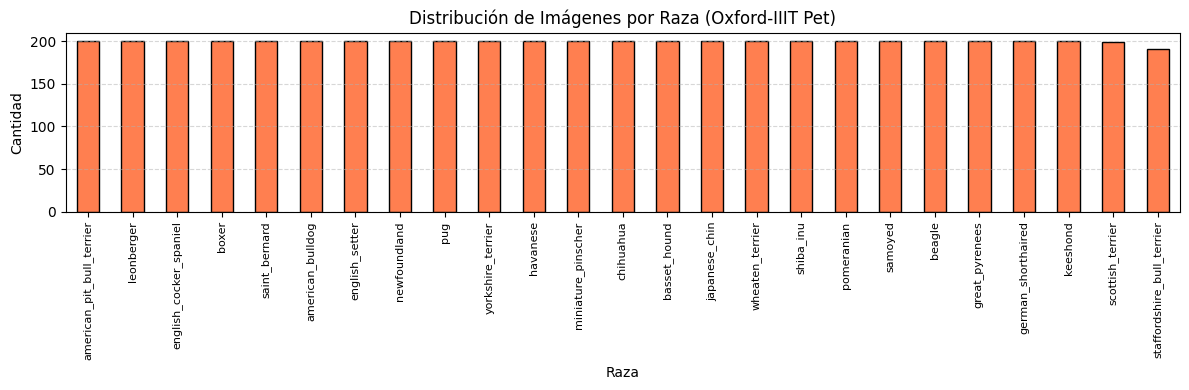


Visualización de una muestra de ejemplos por clase


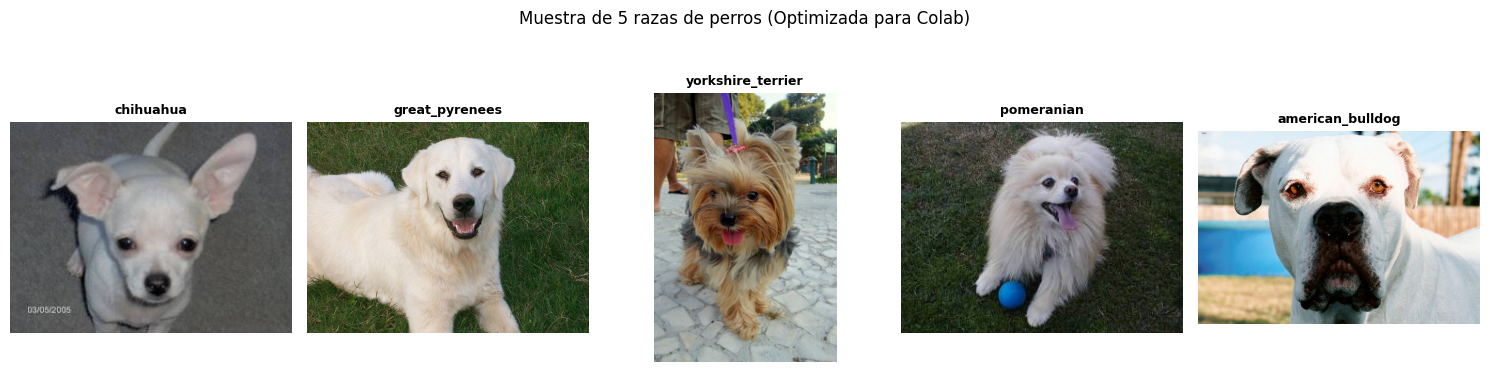

Imágenes cargadas: 4990
Train: 3992 | Test: 998
Forma de cada imagen: (164, 164, 3)

Mapa índice -> raza:
   0 -> american_bulldog
   1 -> american_pit_bull_terrier
   2 -> basset_hound
   3 -> beagle
   4 -> boxer
   5 -> chihuahua
   6 -> english_cocker_spaniel
   7 -> english_setter
   8 -> german_shorthaired
   9 -> great_pyrenees
  10 -> havanese
  11 -> japanese_chin
  12 -> keeshond
  13 -> leonberger
  14 -> miniature_pinscher
  15 -> newfoundland
  16 -> pomeranian
  17 -> pug
  18 -> saint_bernard
  19 -> samoyed
  20 -> scottish_terrier
  21 -> shiba_inu
  22 -> staffordshire_bull_terrier
  23 -> wheaten_terrier
  24 -> yorkshire_terrier

Entrenando MLP (Regularizado: False)
Epoch 1/20
107/107 - 9s - 83ms/step - accuracy: 0.0595 - loss: 3.3892 - val_accuracy: 0.0417 - val_loss: 3.5126 - learning_rate: 1.0000e-04
Epoch 2/20
107/107 - 4s - 35ms/step - accuracy: 0.0855 - loss: 3.2024 - val_accuracy: 0.0818 - val_loss: 3.3003 - learning_rate: 1.0000e-04
Epoch 3/20
107/107 - 3s -

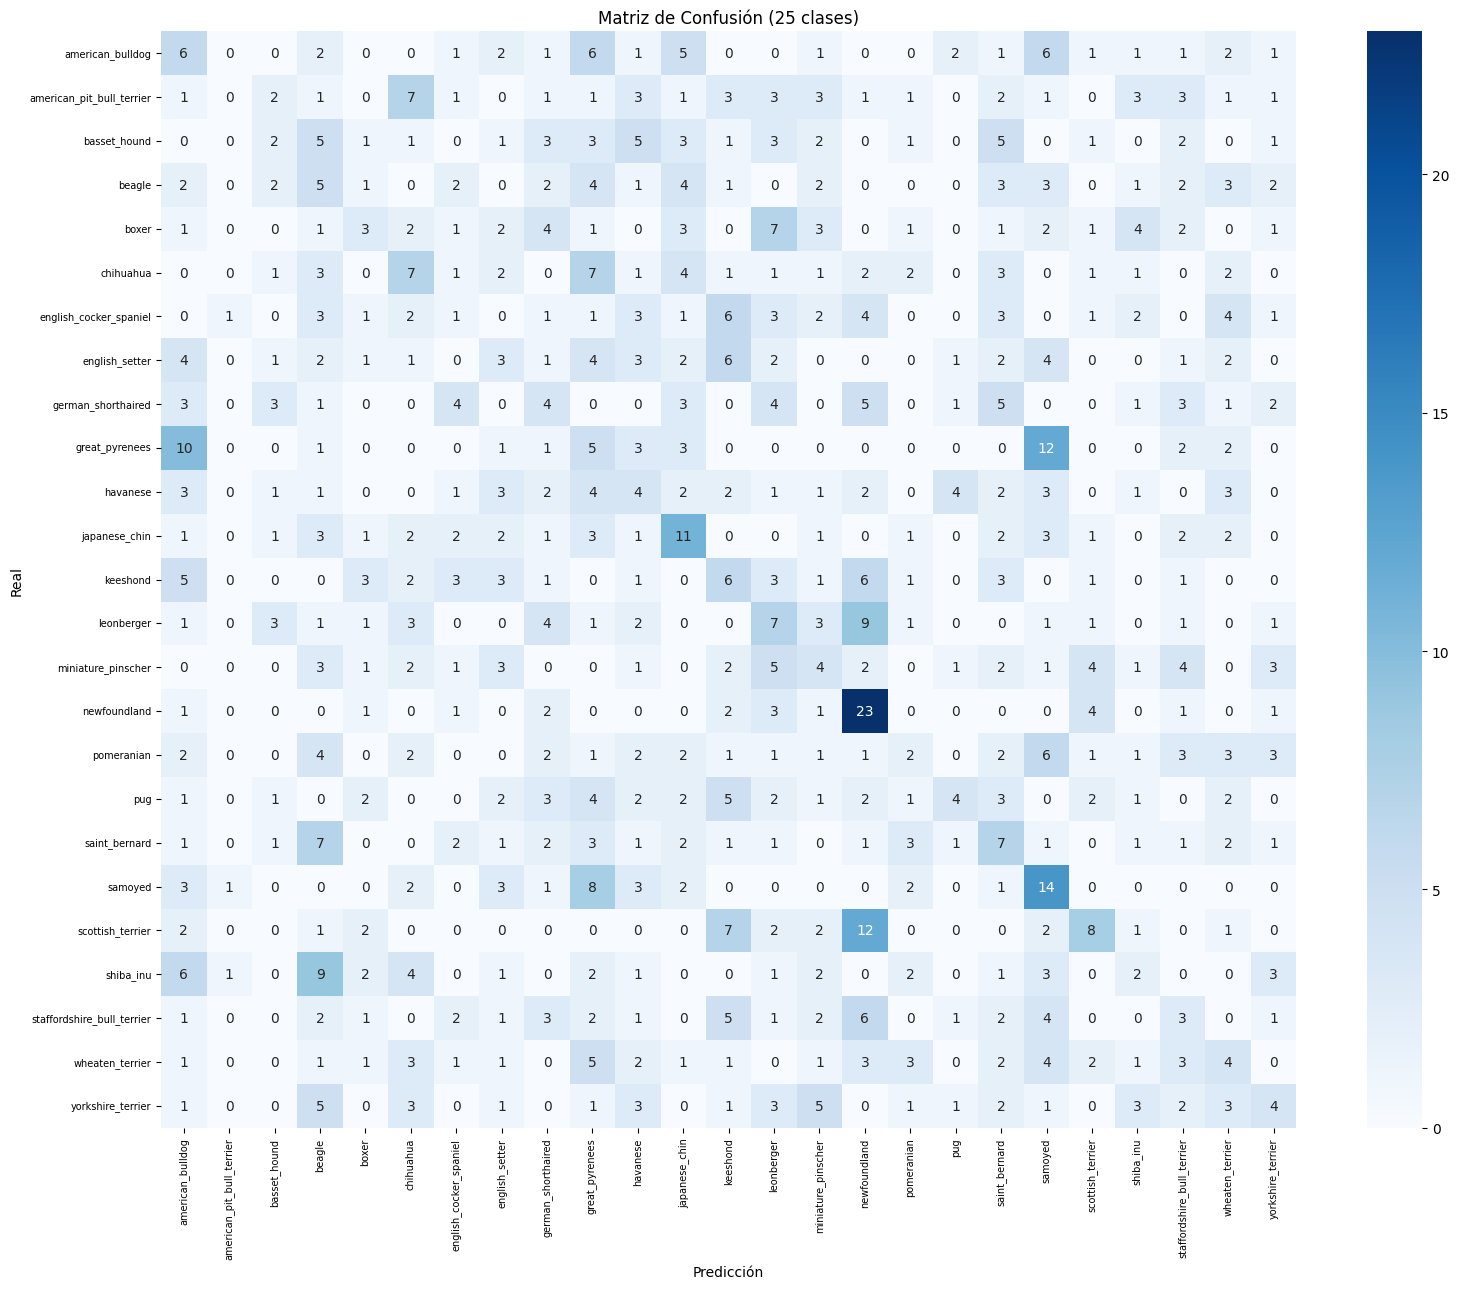


Top 15 confusiones (Real -> Pred):
   12 scottish_terrier -> newfoundland
   12 great_pyrenees -> samoyed
   10 great_pyrenees -> american_bulldog
    9 shiba_inu -> beagle
    9 leonberger -> newfoundland
    8 samoyed -> great_pyrenees
    7 scottish_terrier -> keeshond
    7 saint_bernard -> beagle
    7 chihuahua -> great_pyrenees
    7 boxer -> leonberger
    7 american_pit_bull_terrier -> chihuahua
    6 staffordshire_bull_terrier -> newfoundland
    6 shiba_inu -> american_bulldog
    6 pomeranian -> samoyed
    6 keeshond -> newfoundland

--- Reporte de Clasificación Multiclase (25 clases) ---
                            precision  recall  f1-score   support
american_bulldog               0.1071  0.1500    0.1250   40.0000
american_pit_bull_terrier      0.0000  0.0000    0.0000   40.0000
basset_hound                   0.1111  0.0500    0.0690   40.0000
beagle                         0.0820  0.1250    0.0990   40.0000
boxer                          0.1364  0.0750    0.0968   40

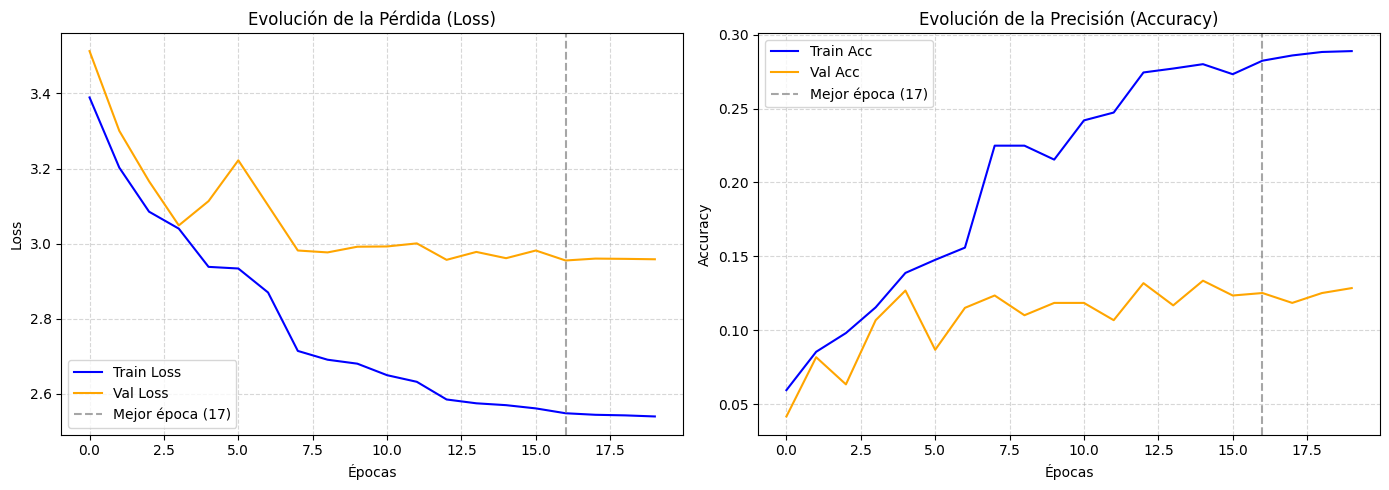

Resumen de las curvas de aprendizaje
Épocas ejecutadas       : 20
Mejor época (val_loss)  : 17
Accuracy train (mejor)  : 0.2823
Accuracy val (mejor)    : 0.1252
Brecha (train - val)    : 0.1571 (15.71 puntos)
Brecha en la última época: 0.1603
Diagnóstico             : Underfitting
Justificación           : La accuracy es baja incluso en train (0.282) y la brecha con validación es pequeña (15.7 puntos).
Aciertos: 139 / 998
Errores: 859


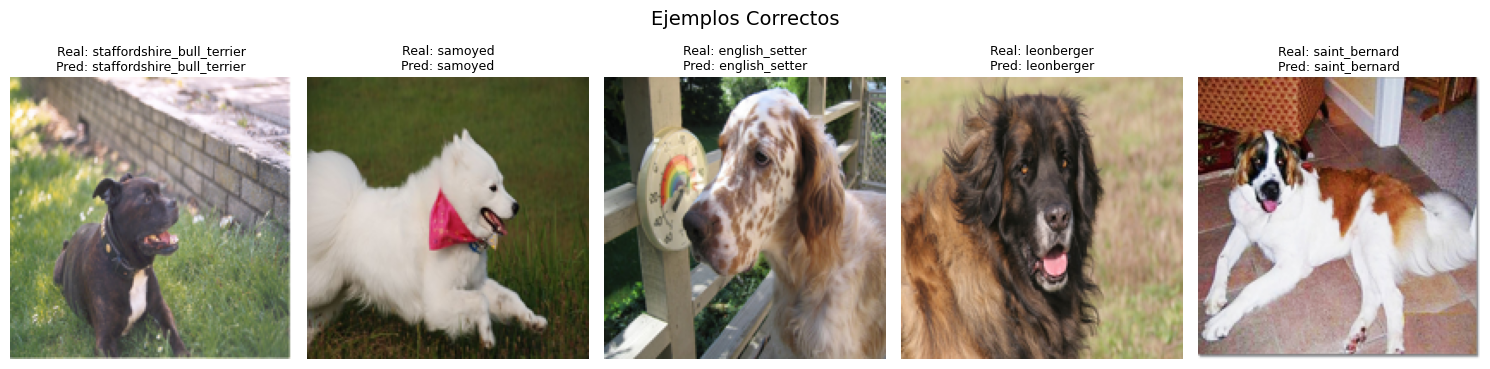

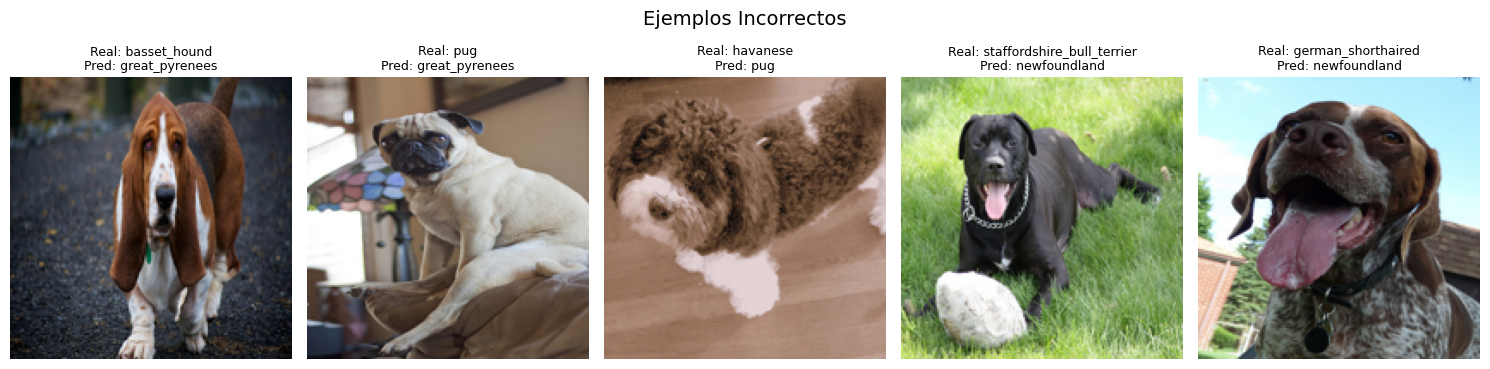


Explicación para la imagen de prueba #14
Clase Real : newfoundland
Predicción : newfoundland (p=0.4561)
Generando explicación con LIME para el modelo MLP...


  0%|          | 0/100 [00:00<?, ?it/s]

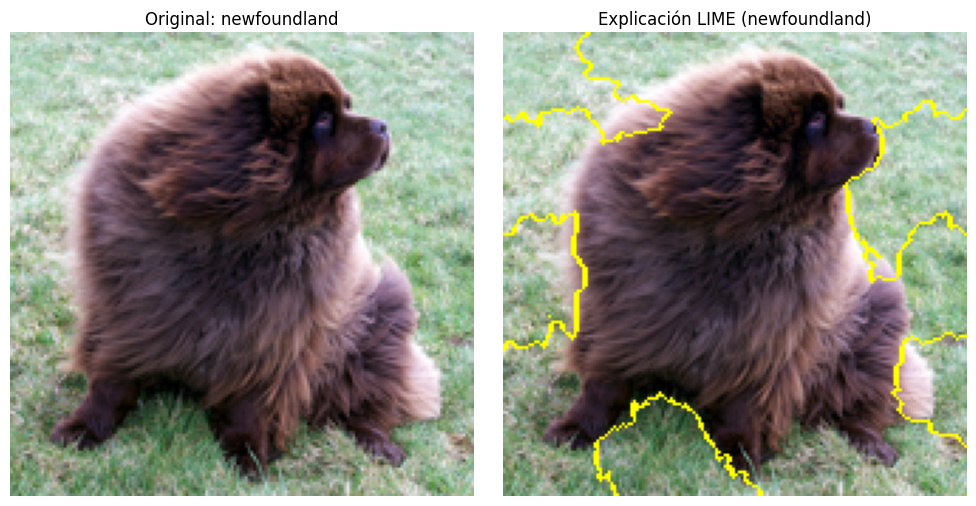

REPORTE FINAL: MLP Base

1. Resumen general del modelo
           Indicador      Valor
   Nombre del modelo   MLP Base
Número de parámetros 20,692,505
   Épocas ejecutadas         20
            Accuracy     0.1393
   Precision (macro)     0.1292
      Recall (macro)     0.1392
    F1 Score (macro)     0.1273
ROC AUC (ovr, macro)      0.705

2. Diagnóstico del entrenamiento
Diagnóstico        : Underfitting
Justificación      : La accuracy es baja incluso en train (0.282) y la brecha con validación es pequeña (15.7 puntos).
Mejor época        : 17 de 20
Accuracy train/val : 0.2823 / 0.1252
Brecha (train-val) : 15.71 puntos

3. Auditoría XAI
Herramienta    : LIME
Clase real     : newfoundland
Clase predicha : newfoundland
Probabilidad   : 0.4561


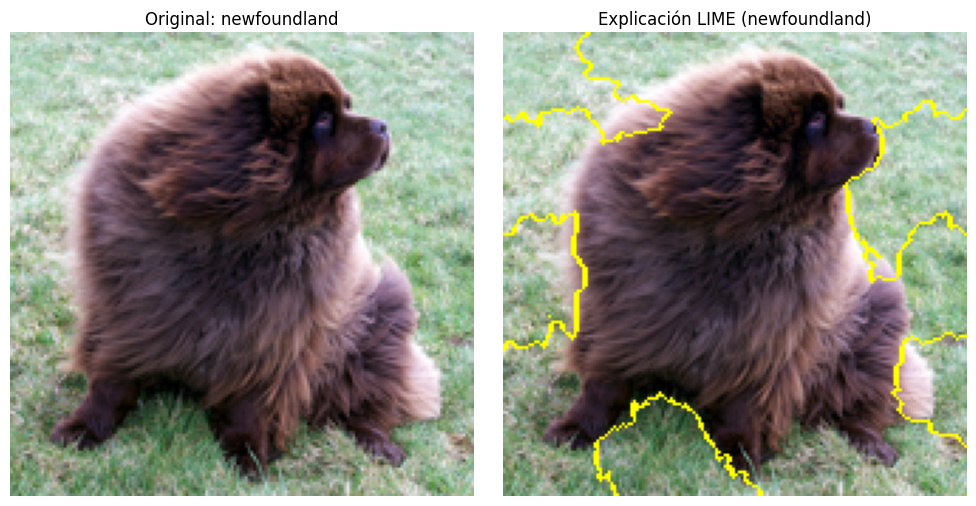


4. Tabla resumen para comparación
Modelo           MLP Base
Parámetros       20692505
Épocas                 20
Mejor época            17
Accuracy           0.1393
Top-5              0.4429
Precision          0.1292
Recall             0.1392
F1                 0.1273
ROC AUC             0.705
Acc train          0.2823
Acc val            0.1252
Brecha             0.1571
Diagnóstico  Underfitting
XAI                  LIME

5. Conclusión técnica
El modelo alcanza un desempeño bajo: accuracy 0.139, F1 macro 0.127 y top-5 0.443 (el azar con 25 clases sería 0.040).
El diagnóstico de las curvas es «Underfitting», con una brecha train-val de 15.7 puntos en la mejor época (17).
La auditoría con LIME sobre una imagen de newfoundland (predicha como newfoundland, p=0.46) debe interpretarse visualmente. Una sola imagen no basta para generalizar la conclusión.
Fortalezas: mejores clases por F1: newfoundland (0.39), samoyed (0.25), japanese_chin (0.24).
Limitaciones: clases más débiles: american_pit

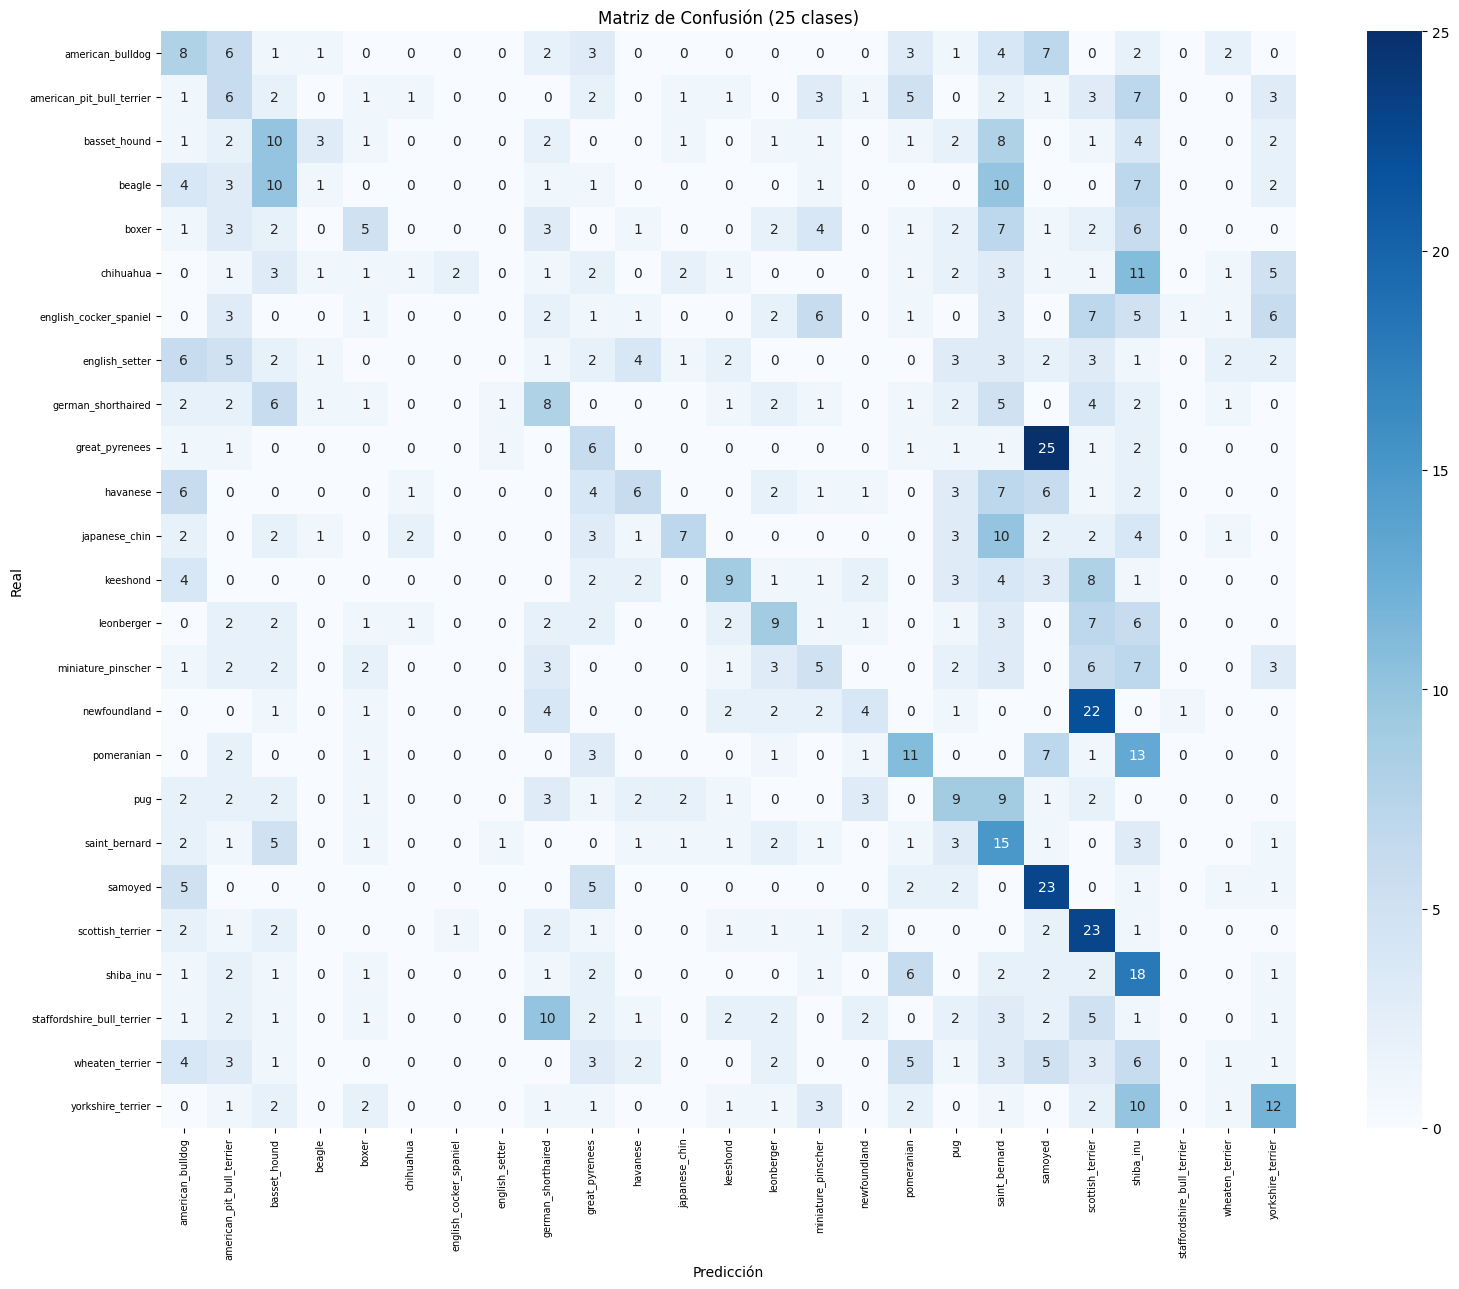


Top 15 confusiones (Real -> Pred):
   25 great_pyrenees -> samoyed
   22 newfoundland -> scottish_terrier
   13 pomeranian -> shiba_inu
   11 chihuahua -> shiba_inu
   10 yorkshire_terrier -> shiba_inu
   10 staffordshire_bull_terrier -> german_shorthaired
   10 japanese_chin -> saint_bernard
   10 beagle -> saint_bernard
   10 beagle -> basset_hound
    9 pug -> saint_bernard
    8 keeshond -> scottish_terrier
    8 basset_hound -> saint_bernard
    7 pomeranian -> samoyed
    7 miniature_pinscher -> shiba_inu
    7 leonberger -> scottish_terrier

--- Reporte de Clasificación Multiclase (25 clases) ---
                            precision  recall  f1-score   support
american_bulldog               0.1481  0.2000    0.1702   40.0000
american_pit_bull_terrier      0.1200  0.1500    0.1333   40.0000
basset_hound                   0.1754  0.2500    0.2062   40.0000
beagle                         0.1111  0.0250    0.0408   40.0000
boxer                          0.2381  0.1250    0.1639   

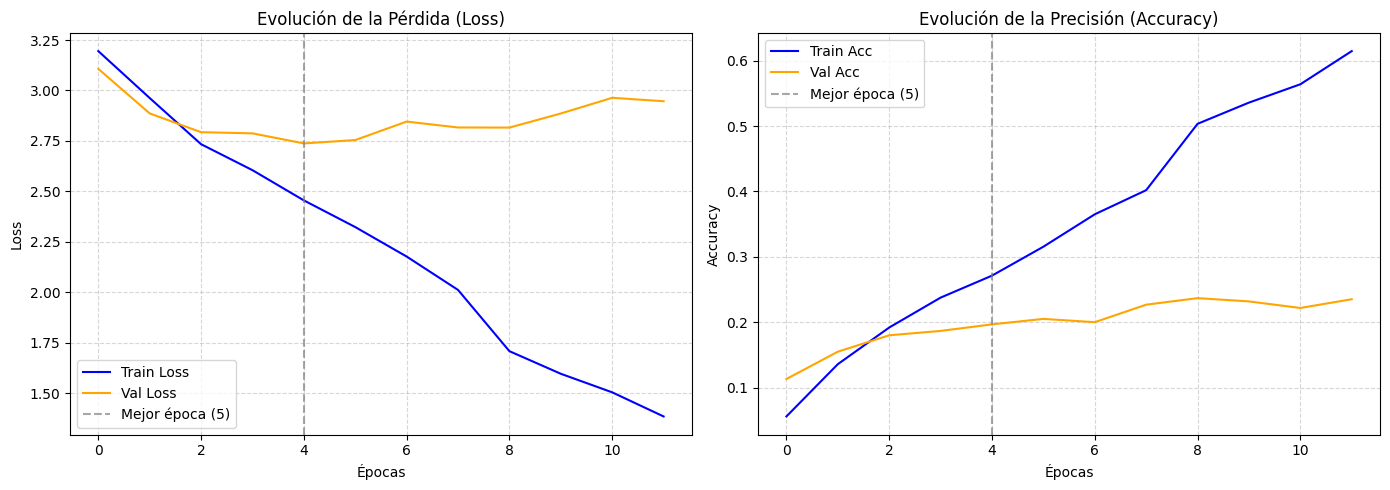

Resumen de las curvas de aprendizaje
Épocas ejecutadas       : 12
Mejor época (val_loss)  : 5
Accuracy train (mejor)  : 0.2714
Accuracy val (mejor)    : 0.1970
Brecha (train - val)    : 0.0744 (7.44 puntos)
Brecha en la última época: 0.3791
Diagnóstico             : Underfitting
Justificación           : La accuracy es baja incluso en train (0.271) y la brecha con validación es pequeña (7.4 puntos).
Aciertos: 197 / 998
Errores: 801


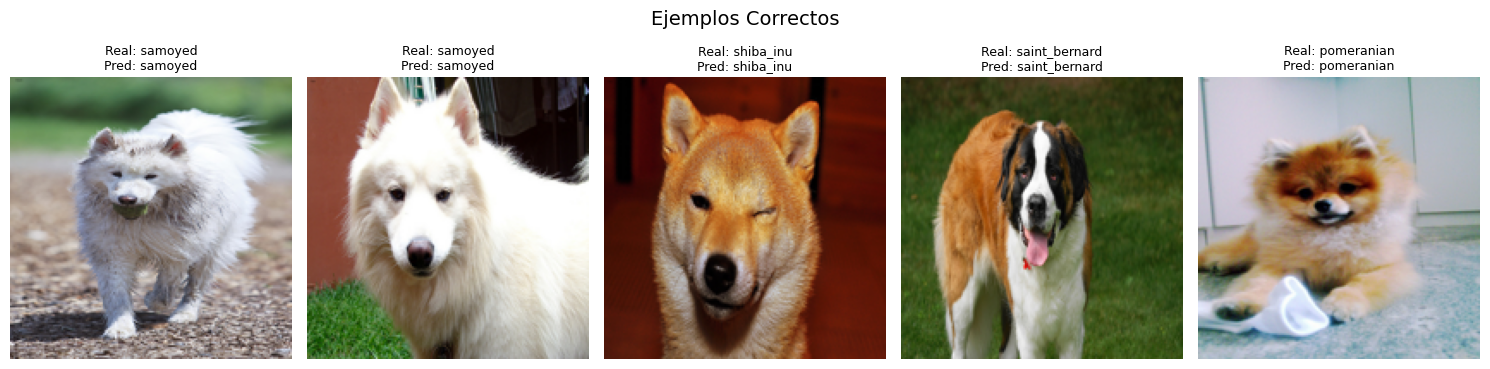

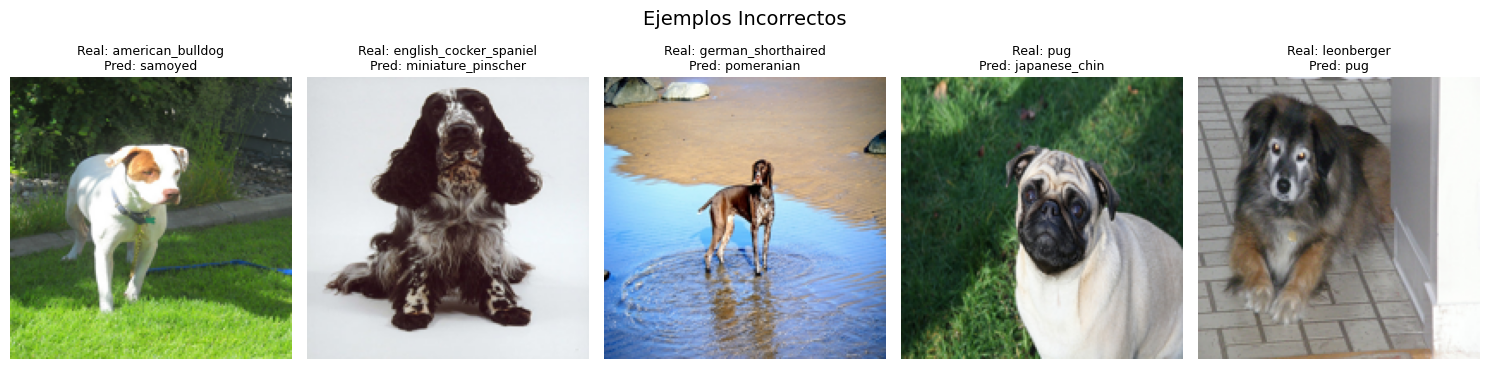


Explicación para la imagen de prueba #8
Clase Real : boxer
Predicción : boxer (p=0.1649)
Generando explicación con Grad-CAM para el modelo CNN...
No se pudo generar la explicación de Grad-CAM: The layer CNN_Base_Razas_Perro has never been called and thus has no defined output.
REPORTE FINAL: CNN Base

1. Resumen general del modelo
           Indicador     Valor
   Nombre del modelo  CNN Base
Número de parámetros 6,948,697
   Épocas ejecutadas        12
            Accuracy    0.1974
   Precision (macro)    0.1868
      Recall (macro)     0.197
    F1 Score (macro)    0.1705
ROC AUC (ovr, macro)    0.7981

2. Diagnóstico del entrenamiento
Diagnóstico        : Underfitting
Justificación      : La accuracy es baja incluso en train (0.271) y la brecha con validación es pequeña (7.4 puntos).
Mejor época        : 5 de 12
Accuracy train/val : 0.2714 / 0.1970
Brecha (train-val) : 7.44 puntos

3. Auditoría XAI
Herramienta    : Ninguna
Clase real     : boxer
Clase predicha : boxer
Probabilidad 

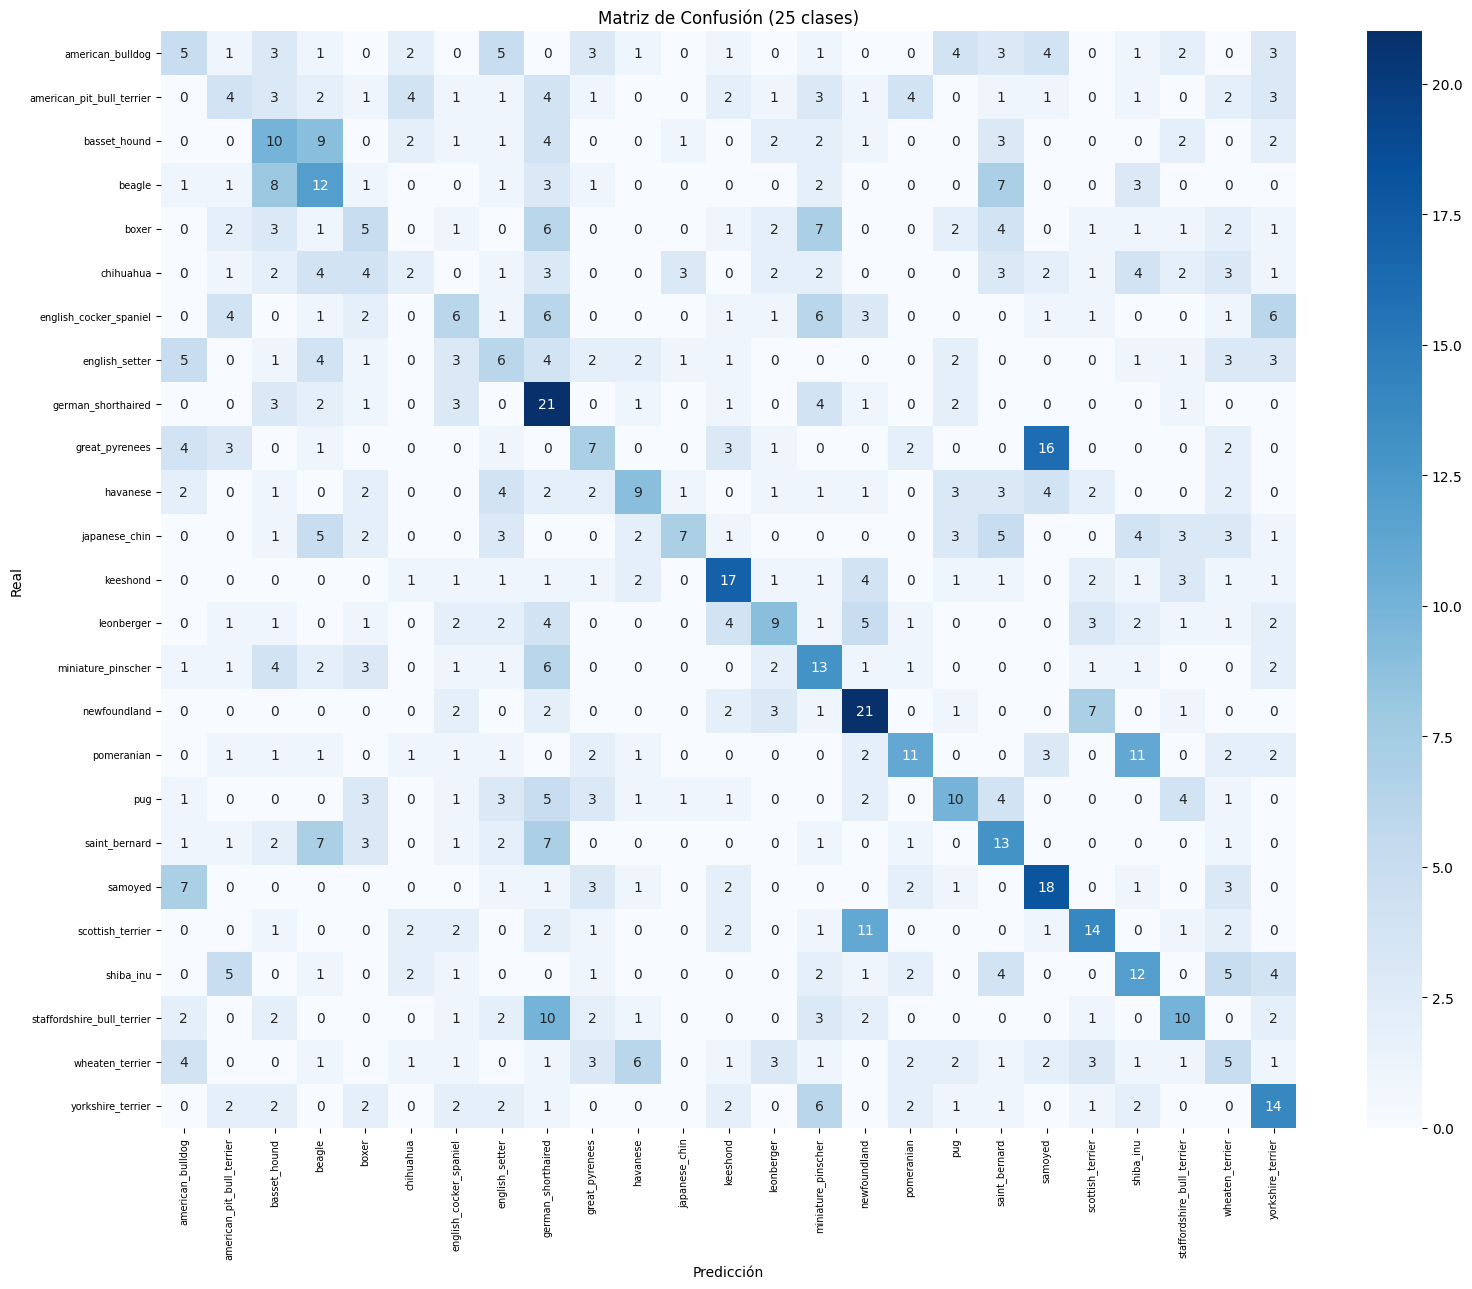


Top 15 confusiones (Real -> Pred):
   16 great_pyrenees -> samoyed
   11 scottish_terrier -> newfoundland
   11 pomeranian -> shiba_inu
   10 staffordshire_bull_terrier -> german_shorthaired
    9 basset_hound -> beagle
    8 beagle -> basset_hound
    7 samoyed -> american_bulldog
    7 saint_bernard -> german_shorthaired
    7 saint_bernard -> beagle
    7 newfoundland -> scottish_terrier
    7 boxer -> miniature_pinscher
    7 beagle -> saint_bernard
    6 yorkshire_terrier -> miniature_pinscher
    6 wheaten_terrier -> havanese
    6 miniature_pinscher -> german_shorthaired

--- Reporte de Clasificación Multiclase (25 clases) ---
                            precision  recall  f1-score   support
american_bulldog               0.1515  0.1250    0.1370   40.0000
american_pit_bull_terrier      0.1481  0.1000    0.1194   40.0000
basset_hound                   0.2083  0.2500    0.2273   40.0000
beagle                         0.2222  0.3000    0.2553   40.0000
boxer                      

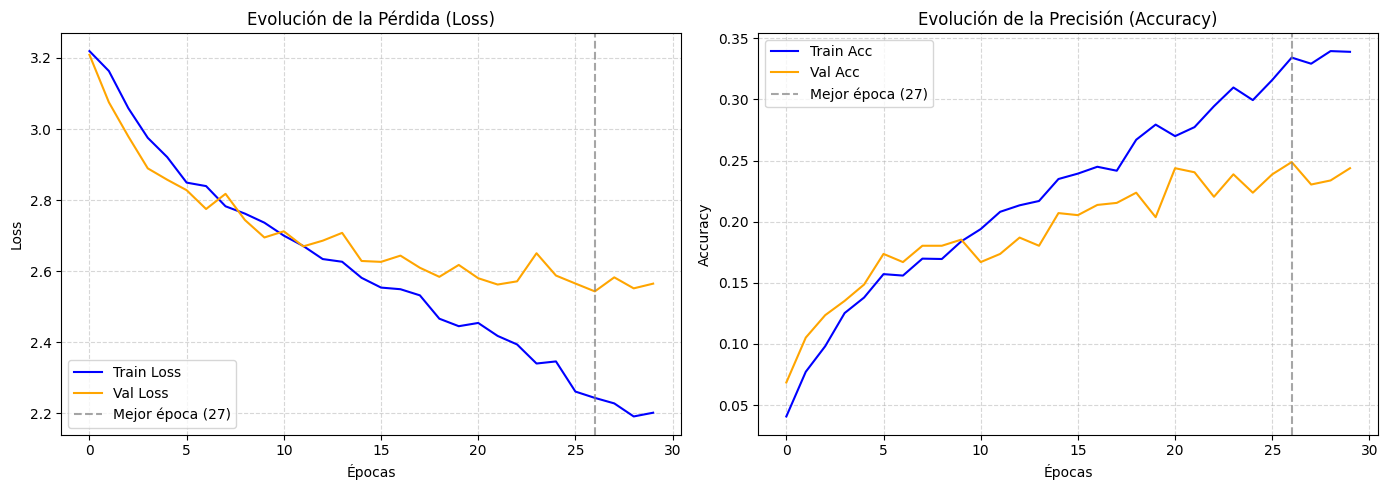

Resumen de las curvas de aprendizaje
Épocas ejecutadas       : 30
Mejor época (val_loss)  : 27
Accuracy train (mejor)  : 0.3342
Accuracy val (mejor)    : 0.2487
Brecha (train - val)    : 0.0855 (8.55 puntos)
Brecha en la última época: 0.0952
Diagnóstico             : Underfitting
Justificación           : La accuracy es baja incluso en train (0.334) y la brecha con validación es pequeña (8.5 puntos).
Aciertos: 261 / 998
Errores: 737


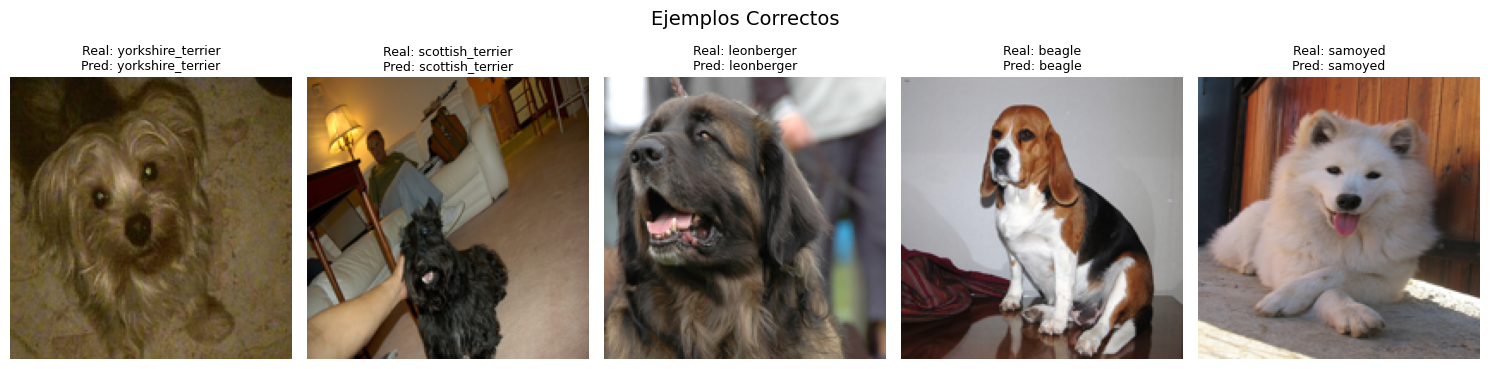

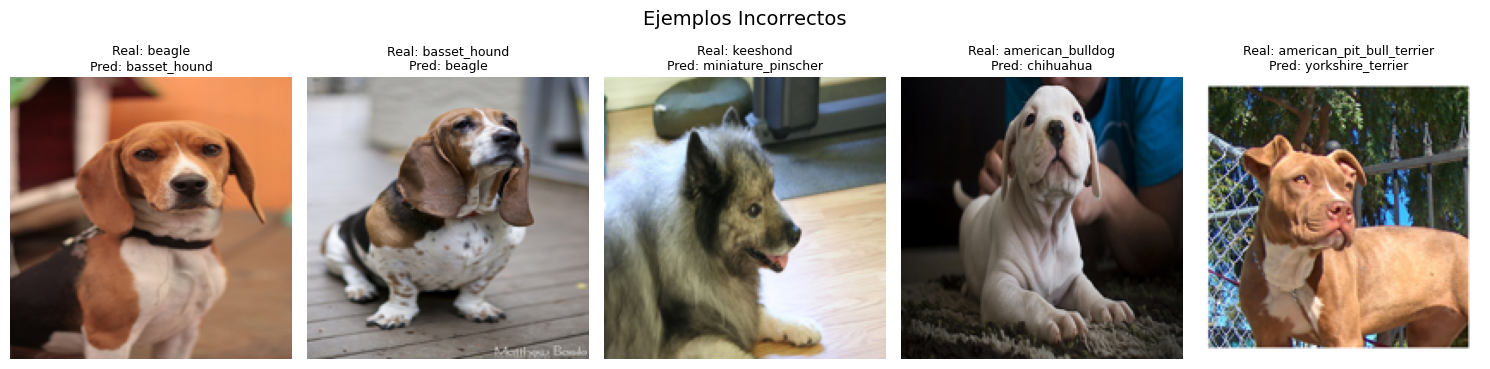


Explicación para la imagen de prueba #1
Clase Real : american_pit_bull_terrier
Predicción : american_pit_bull_terrier (p=0.1216)
Generando explicación con Grad-CAM para el modelo CNN...
No se pudo generar la explicación de Grad-CAM: The layer CNN_Razas_Perro has never been called and thus has no defined output.
REPORTE FINAL: CNN Regularizado

1. Resumen general del modelo
           Indicador            Valor
   Nombre del modelo CNN Regularizado
Número de parámetros        6,948,697
   Épocas ejecutadas               30
            Accuracy           0.2615
   Precision (macro)           0.2647
      Recall (macro)           0.2615
    F1 Score (macro)           0.2533
ROC AUC (ovr, macro)           0.8287

2. Diagnóstico del entrenamiento
Diagnóstico        : Underfitting
Justificación      : La accuracy es baja incluso en train (0.334) y la brecha con validación es pequeña (8.5 puntos).
Mejor época        : 27 de 30
Accuracy train/val : 0.3342 / 0.2487
Brecha (train-val) : 8.55 pu

,Modelo,Parámetros,Épocas,Mejor época,Accuracy,Top-5,Precision,Recall,F1,ROC AUC,Acc train,Acc val,Brecha,Diagnóstico,XAI
0,MLP Base,20692505,20,17,0.1393,0.4429,0.1292,0.1392,0.1273,0.7050,0.2823,0.1252,0.1571,Underfitting,LIME
1,CNN Base,6948697,12,5,0.1974,0.5752,0.1868,0.1970,0.1705,0.7981,0.2714,0.1970,0.0744,Underfitting,Ninguna
2,CNN Regularizado,6948697,30,27,0.2615,0.6573,0.2647,0.2615,0.2533,0.8287,0.3342,0.2487,0.0855,Underfitting,Ninguna


In [12]:
# Asegurar que las dependencias de XAI (LIME) estén instaladas
try:
    import lime
    import skimage
except ImportError:
    print("Instalando dependencias necesarias para explicabilidad (lime y scikit-image)")
    !pip install lime scikit-image --quiet

# ======================================================
# 1. Cargar y Preprocesar los datos UNA SOLA VEZ fuera del bucle
# ======================================================
print("Cargando y preparando el dataset para todas las configuraciones...")
df, img_dir, trimap_dir, species_from_breed = cargar_datos_y_trimaps()
analizar_dataset(df, img_dir, sorted(df["breed"].unique()), species_from_breed)
x_train_raw, y_train_raw, x_test_raw, y_test_raw, class_names_raw = cargar_datos(df, img_dir)

(x_train, y_train, x_test, y_test, data_aug, le_breed) = preprocesar(
    x_train_raw, y_train_raw, x_test_raw, y_test_raw
)
class_names = list(le_breed.classes_)
N_RAZAS = len(class_names)

# ======================================================
# 2. Configurar bucle de entrenamiento y evaluación (sin MLP regularizado)
# ======================================================
configuraciones = [
    {"tipo_modelo": "MLP", "regularizacion": False, "epochs": 20, "batch_size": 32},
    {"tipo_modelo": "CNN", "regularizacion": False, "epochs": 30, "batch_size": 32},
    {"tipo_modelo": "CNN", "regularizacion": True, "epochs": 30, "batch_size": 32},
]

reportes = []

for config in configuraciones:
    tipo = config["tipo_modelo"]
    reg = config["regularizacion"]

    print("\n" + "=" * 80)
    print(f"Entrenando {tipo} (Regularizado: {reg})")
    print("=" * 80)

    tf.keras.backend.clear_session()

    # Construcción
    modelo = construir_modelo(
        tipo_modelo=tipo,
        regularizacion=reg,
        data_augmentation=data_aug,
        N_RAZAS=N_RAZAS
    )

    # Entrenamiento
    modelo, history, predicciones = entrenar(
        modelo,
        x_train,
        y_train,
        x_test,
        y_test,
        regularizacion=reg,
        epochs=config["epochs"],
        batch_size=config["batch_size"]
    )

    # Métricas y Evaluación
    metrics, matriz, reporte = evaluar_metricas(
        modelo, x_test, y_test, class_names
    )

    # Curvas de Aprendizaje
    learning_curves = evaluar_aprendizaje(history)

    # Explainable AI
    explicacion = explicar_modelo(
        modelo,
        x_test,
        y_test,
        class_names,
        tipo_modelo=tipo,
        indice_imagen=0,
        ultima_capa_conv=None
    )

    # Generación del Reporte Individual
    reporte_final = generar_reporte(
        nombre_modelo=f"{tipo} {'Regularizado' if reg else 'Base'}",
        modelo=modelo,
        metrics=metrics,
        matriz_confusion=matriz,
        classification_report_df=reporte,
        learning_curves=learning_curves,
        explanation_result=explicacion
    )

    reportes.append(reporte_final)

    # Cerrar figuras activas para prevenir fugas de memoria RAM en Colab
    plt.close('all')

# Comparación final de las tres arquitecturas
reporte_comparativo = pd.concat(
    [r["tabla_resumen"] for r in reportes],
    ignore_index=True
)
display(reporte_comparativo)